In [107]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/manishkr1754/cardekho-used-car-data/cardekho_dataset.csv


In [108]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(f"\nFolder: {dirname}")
    for filename in filenames:
        print(filename)


Folder: /kaggle/input

Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/manishkr1754

Folder: /kaggle/input/datasets/manishkr1754/cardekho-used-car-data
cardekho_dataset.csv


#  AutoValue AI: Used Car Price Prediction

##  Project Overview

This project aims to develop a machine learning regression model capable of predicting the selling price of used cars based on their characteristics such as brand, model, vehicle age, mileage, engine specifications, fuel type, transmission, and other relevant features.

The project follows a complete machine learning workflow, including:

- Data Loading
- Data Inspection
- Data Cleaning
- Feature Engineering
- Exploratory Data Analysis (EDA)
- Data Preprocessing
- Model Training
- Model Evaluation
- Model Comparison
- Feature Importance Analysis
- Model Serialization

---

##  Objective

The main objective is to build an accurate regression model that estimates the market value of used cars and compares the performance of multiple machine learning algorithms using standard evaluation metrics.


# 1 — Import Libraries

In [297]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV
import joblib
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


import joblib
import warnings
warnings.filterwarnings("ignore")

# Visualization Settings

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


#  Load Dataset

In this section, we load the dataset and preview the first few records to understand its structure.

In [110]:
# Load dataset
df = pd.read_csv(
    "/kaggle/input/datasets/manishkr1754/cardekho-used-car-data/cardekho_dataset.csv"
)

# Display the first five rows
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


# Initial inspection

Before performing any preprocessing, we inspect the dataset to understand its dimensions, data types, missing values, duplicate records, and basic statistical properties.

In [111]:
print("Dataset Shape:", df.shape)

Dataset Shape: (15411, 14)


In [112]:
df.columns.tolist()

['Unnamed: 0',
 'car_name',
 'brand',
 'model',
 'vehicle_age',
 'km_driven',
 'seller_type',
 'fuel_type',
 'transmission_type',
 'mileage',
 'engine',
 'max_power',
 'seats',
 'selling_price']

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [114]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,15411.0,NaN,NaN,NaN,9811.857699,5643.418542,0.0,4906.5,9872.0,14668.5,19543.0
car_name,15411,121,Hyundai i20,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,15411,32,Maruti,4992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,15411,120,i20,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_age,15411.0,NaN,NaN,NaN,6.036338,3.013291,0.0,4.0,6.0,8.0,29.0
km_driven,15411.0,NaN,NaN,NaN,55616.480631,51618.548422,100.0,30000.0,50000.0,70000.0,3800000.0
seller_type,15411,3,Dealer,9539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,15411,5,Petrol,7643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission_type,15411,2,Manual,12225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,15411.0,NaN,NaN,NaN,19.701151,4.171265,4.0,17.0,19.67,22.7,33.54


In [115]:
df.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [116]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


# Data Cleaning

Data cleaning is an essential preprocessing step to improve data quality before training machine learning models.

The following tasks will be performed:

- Check and handle missing values
- Remove duplicate records
- Inspect categorical values for inconsistencies
- Verify data types

In [117]:
# Check missing values
missing_values = df.isnull().sum()

missing_values

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [118]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_percentage.sort_values(ascending=False)

Unnamed: 0           0.0
car_name             0.0
brand                0.0
model                0.0
vehicle_age          0.0
km_driven            0.0
seller_type          0.0
fuel_type            0.0
transmission_type    0.0
mileage              0.0
engine               0.0
max_power            0.0
seats                0.0
selling_price        0.0
dtype: float64

In [119]:
print("Duplicates Before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates After:", df.duplicated().sum())

Duplicates Before: 0
Duplicates After: 0


In [120]:
df.dtypes

Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

In [121]:
categorical_columns = df.select_dtypes(include="object").columns

categorical_columns

Index(['car_name', 'brand', 'model', 'seller_type', 'fuel_type',
       'transmission_type'],
      dtype='object')

In [122]:
#check unique values
for column in categorical_columns:
    print(f"\n{'='*40}")
    print(column)
    print(df[column].unique())


car_name
['Maruti Alto' 'Hyundai Grand' 'Hyundai i20' 'Ford Ecosport'
 'Maruti Wagon R' 'Hyundai i10' 'Hyundai Venue' 'Maruti Swift'
 'Hyundai Verna' 'Renault Duster' 'Mini Cooper' 'Maruti Ciaz'
 'Mercedes-Benz C-Class' 'Toyota Innova' 'Maruti Baleno'
 'Maruti Swift Dzire' 'Volkswagen Vento' 'Hyundai Creta' 'Honda City'
 'Mahindra Bolero' 'Toyota Fortuner' 'Renault KWID' 'Honda Amaze'
 'Hyundai Santro' 'Mahindra XUV500' 'Mahindra KUV100' 'Maruti Ignis'
 'Datsun RediGO' 'Mahindra Scorpio' 'Mahindra Marazzo' 'Ford Aspire'
 'Ford Figo' 'Maruti Vitara' 'Tata Tiago' 'Volkswagen Polo' 'Kia Seltos'
 'Maruti Celerio' 'Datsun GO' 'BMW 5' 'Honda CR-V' 'Ford Endeavour'
 'Mahindra KUV' 'Honda Jazz' 'BMW 3' 'Audi A4' 'Tata Tigor'
 'Maruti Ertiga' 'Tata Safari' 'Mahindra Thar' 'Tata Hexa'
 'Land Rover Rover' 'Maruti Eeco' 'Audi A6' 'Mercedes-Benz E-Class'
 'Audi Q7' 'BMW Z4' 'BMW 6' 'Jaguar XF' 'BMW X5' 'MG Hector' 'Honda Civic'
 'Isuzu D-Max' 'Porsche Cayenne' 'BMW X1' 'Skoda Rapid' 'Ford Freestyl

In [123]:
#Check Category Counts
for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts())


car_name
car_name
Hyundai i20              906
Maruti Swift Dzire       890
Maruti Swift             781
Maruti Alto              778
Honda City               757
                        ... 
Mercedes-AMG C             1
Rolls-Royce Ghost          1
Maserati Quattroporte      1
Isuzu MUX                  1
Force Gurkha               1
Name: count, Length: 121, dtype: int64

brand
brand
Maruti           4992
Hyundai          2982
Honda            1485
Mahindra         1011
Toyota            793
Ford              790
Volkswagen        620
Renault           536
BMW               439
Tata              430
Mercedes-Benz     337
Skoda             334
Audi              192
Datsun            170
Jaguar             59
Land Rover         51
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus              10
Isuzu               8
Bentley             3
Maserati            2
ISUZU           

In [124]:
# Remove unnecessary index column
df.drop(columns=["Unnamed: 0"], inplace=True)

print("Column removed successfully.")

Column removed successfully.


In [125]:
df.columns

Index(['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='object')

In [126]:
df.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


### 5.5 Handle Inconsistent Categorical Values

Categorical values were inspected for inconsistencies. The `brand` column contained two different representations of the same manufacturer (`Isuzu` and `ISUZU`).

To ensure consistency, these values were standardized before model training.

In [127]:
# Standardize inconsistent brand names
df["brand"] = df["brand"].replace({
    "ISUZU": "Isuzu"
})

In [128]:
df["brand"].value_counts()

brand
Maruti           4992
Hyundai          2982
Honda            1485
Mahindra         1011
Toyota            793
Ford              790
Volkswagen        620
Renault           536
BMW               439
Tata              430
Mercedes-Benz     337
Skoda             334
Audi              192
Datsun            170
Jaguar             59
Land Rover         51
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus              10
Isuzu              10
Bentley             3
Maserati            2
Ferrari             1
Mercedes-AMG        1
Rolls-Royce         1
Force               1
Name: count, dtype: int64

#  Feature Engineering

Feature engineering is the process of creating new features or improving existing ones to enhance the performance of machine learning models.

According to the project requirements, the following feature engineering tasks were expected:

- Calculate the car age from the manufacturing year.
- Extract the car brand from the car name.

### Note

After inspecting the dataset, it was observed that the required features, `vehicle_age` and `brand`, are already available.

The `vehicle_age` column represents the age of each vehicle, while the `brand` column identifies the manufacturer of the car.

Since these features are already provided in the dataset, they are verified for consistency and used directly in the subsequent analysis and model training.

In [129]:
# Display the relevant columns
df[["car_name", "brand", "vehicle_age"]].head(10)

,car_name,brand,vehicle_age
0,Maruti Alto,Maruti,9
1,Hyundai Grand,Hyundai,5
2,Hyundai i20,Hyundai,11
3,Maruti Alto,Maruti,9
4,Ford Ecosport,Ford,6
5,Maruti Wagon R,Maruti,8
6,Hyundai i10,Hyundai,8
7,Maruti Wagon R,Maruti,3
8,Hyundai Venue,Hyundai,2
9,Maruti Swift,Maruti,4


In [130]:
# Extract the first word from the car name
df["extracted_brand"] = df["car_name"].str.split().str[0]

# Compare the extracted brand with the existing brand column
df[["car_name", "brand", "extracted_brand"]].head(10)

,car_name,brand,extracted_brand
0,Maruti Alto,Maruti,Maruti
1,Hyundai Grand,Hyundai,Hyundai
2,Hyundai i20,Hyundai,Hyundai
3,Maruti Alto,Maruti,Maruti
4,Ford Ecosport,Ford,Ford
5,Maruti Wagon R,Maruti,Maruti
6,Hyundai i10,Hyundai,Hyundai
7,Maruti Wagon R,Maruti,Maruti
8,Hyundai Venue,Hyundai,Hyundai
9,Maruti Swift,Maruti,Maruti


In [131]:
# Verify whether the extracted brand matches the existing brand
(df["brand"] == df["extracted_brand"]).value_counts()

True     15358
False       53
Name: count, dtype: int64

### Verify Brand Consistency

To validate the existing `brand` feature, the first word of each `car_name` was extracted and compared with the corresponding value in the `brand` column.

A case-insensitive comparison was performed to avoid false mismatches caused solely by differences in letter capitalization.

Most records matched successfully. The remaining mismatches were manually inspected and found to be associated with vehicles whose manufacturer name consists of multiple words, such as **Land Rover**. In these cases, extracting only the first word from `car_name` results in `Land` instead of the complete manufacturer name `Land Rover`.

Based on this inspection, the existing `brand` column was considered the most reliable representation of the vehicle manufacturer and was retained for the subsequent analysis and model development.

In [132]:
mismatches = df[df["brand"] != df["extracted_brand"]]

mismatches[["car_name", "brand", "extracted_brand"]]

,car_name,brand,extracted_brand
240,Land Rover Rover,Land Rover,Land
285,Land Rover Rover,Land Rover,Land
318,Land Rover Rover,Land Rover,Land
484,Land Rover Rover,Land Rover,Land
548,Land Rover Rover,Land Rover,Land
897,Land Rover Rover,Land Rover,Land
988,Land Rover Rover,Land Rover,Land
1489,Land Rover Rover,Land Rover,Land
1713,Land Rover Rover,Land Rover,Land
2142,Land Rover Rover,Land Rover,Land


In [133]:
# Remove the temporary verification column
df.drop(columns=["extracted_brand"], inplace=True)

In [134]:
df["brand"] = df["brand"].replace({
    "ISUZU": "Isuzu"
})

In [135]:
df["extracted_brand"] = df["car_name"].str.split().str[0]

In [136]:
(df["brand"] == df["extracted_brand"]).value_counts()

True     15358
False       53
Name: count, dtype: int64

In [137]:
df["brand"].value_counts().loc[df["brand"].value_counts().index.str.contains("ISUZU|Isuzu", case=False)]

brand
Isuzu    10
Name: count, dtype: int64

In [138]:
df[df["car_name"].str.contains("ISUZU", case=False)][
    ["car_name", "brand"]
]

,car_name,brand
399,Isuzu D-Max,Isuzu
1674,Isuzu D-Max,Isuzu
3553,ISUZU MUX,Isuzu
3907,Isuzu D-Max,Isuzu
5056,Isuzu D-Max,Isuzu
10271,Isuzu D-Max,Isuzu
10731,Isuzu D-Max,Isuzu
12564,Isuzu MUX,Isuzu
12836,Isuzu D-Max,Isuzu
14780,ISUZU MUX,Isuzu


In [139]:
print(df["brand"].unique())

['Maruti' 'Hyundai' 'Ford' 'Renault' 'Mini' 'Mercedes-Benz' 'Toyota'
 'Volkswagen' 'Honda' 'Mahindra' 'Datsun' 'Tata' 'Kia' 'BMW' 'Audi'
 'Land Rover' 'Jaguar' 'MG' 'Isuzu' 'Porsche' 'Skoda' 'Volvo' 'Lexus'
 'Jeep' 'Maserati' 'Bentley' 'Nissan' 'Ferrari' 'Mercedes-AMG'
 'Rolls-Royce' 'Force']


In [140]:
(
    df["brand"].str.lower() ==
    df["extracted_brand"].str.lower()
).value_counts()

True     15360
False       51
Name: count, dtype: int64

In [141]:
df[df["brand"] == "Land Rover"]["car_name"].unique()

array(['Land Rover Rover'], dtype=object)

In [142]:
df[df["brand"] == "Land Rover"]["model"].value_counts()

model
Rover    51
Name: count, dtype: int64

In [143]:
# Remove the temporary verification column
df.drop(columns=["extracted_brand"], inplace=True)

print("Temporary verification column removed successfully.")

Temporary verification column removed successfully.


In [144]:
print("Dataset Shape:", df.shape)

Dataset Shape: (15411, 13)


In [145]:
for col in ["brand", "seller_type", "fuel_type", "transmission_type"]:
    print(f"\n{col}")
    print(df[col].value_counts())


brand
brand
Maruti           4992
Hyundai          2982
Honda            1485
Mahindra         1011
Toyota            793
Ford              790
Volkswagen        620
Renault           536
BMW               439
Tata              430
Mercedes-Benz     337
Skoda             334
Audi              192
Datsun            170
Jaguar             59
Land Rover         51
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus              10
Isuzu              10
Bentley             3
Maserati            2
Ferrari             1
Mercedes-AMG        1
Rolls-Royce         1
Force               1
Name: count, dtype: int64

seller_type
seller_type
Dealer              9539
Individual          5699
Trustmark Dealer     173
Name: count, dtype: int64

fuel_type
fuel_type
Petrol      7643
Diesel      7419
CNG          301
LPG           44
Electric       4
Name: count, dtype: int64

transmission_type
tr

In [146]:
df[df["seats"] == 0]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
3217,Honda City,Honda,City,18,40000,Individual,Petrol,Manual,13.00,1493,100.00,0,115000
12619,Nissan Kicks,Nissan,Kicks,2,10000,Individual,Diesel,Manual,19.39,1461,108.49,0,1154000


In [147]:
df["seats"].value_counts().sort_index()

seats
0        2
2        7
4       77
5    12910
6      127
7     1922
8      311
9       55
Name: count, dtype: int64

### Handle Invalid Seat Values

A data quality check identified two records with a seat count of `0`, which is not a valid value for passenger vehicles.

Since only two records were affected and the seat count is clearly a data entry error, the invalid values were replaced with the median seat count of the dataset (`5`). This approach preserves the observations while correcting the invalid entries.

In [148]:
# Calculate the median using only valid seat values
median_seats = int(df.loc[df["seats"] > 0, "seats"].median())

# Replace invalid values
df.loc[df["seats"] == 0, "seats"] = median_seats

print("Invalid seat values corrected.")

Invalid seat values corrected.


In [149]:
df["seats"].value_counts().sort_index()

seats
2        7
4       77
5    12912
6      127
7     1922
8      311
9       55
Name: count, dtype: int64

In [150]:
df.nlargest(10, "km_driven")[
    ["car_name", "km_driven", "vehicle_age", "selling_price"]
]

,car_name,km_driven,vehicle_age,selling_price
15409,Mahindra XUV500,3800000,5,1225000
11903,Mercedes-Benz E-Class,1325000,9,1350000
8772,Toyota Innova,950000,6,950000
4532,Renault Duster,850000,4,850000
6712,Volkswagen Vento,830000,9,380000
10838,Hyundai Creta,825000,6,825000
11615,Volkswagen Polo,820000,5,695000
7323,Ford Ecosport,720000,6,675000
9170,Skoda Rapid,675000,5,675000
7534,Toyota Fortuner,590000,2,2850000


In [151]:
df.nlargest(10, "engine")[
    ["car_name", "engine"]
]

,car_name,engine
10969,Rolls-Royce Ghost,6592
1172,Bentley Continental,5998
10040,Bentley Continental,5998
12997,Bentley Continental,5998
1888,Mercedes-Benz S-Class,5461
3631,Mercedes-Benz S-Class,5461
10608,Mercedes-Benz S-Class,5461
13854,Mercedes-Benz S-Class,5461
5590,Porsche Panamera,4806
9190,Porsche Cayenne,4806


In [152]:
df.nlargest(10, "selling_price")[
    ["car_name", "brand", "selling_price", "vehicle_age"]
]

,car_name,brand,selling_price,vehicle_age
3799,Ferrari GTC4Lusso,Ferrari,39500000,2
10969,Rolls-Royce Ghost,Rolls-Royce,24200000,4
1172,Bentley Continental,Bentley,14500000,9
9722,Mercedes-Benz S-Class,Mercedes-Benz,13000000,3
9364,Porsche Cayenne,Porsche,11100000,4
1888,Mercedes-Benz S-Class,Mercedes-Benz,11000000,5
10989,Mercedes-Benz S-Class,Mercedes-Benz,11000000,2
11000,Land Rover Rover,Land Rover,9200000,4
3096,BMW 7,BMW,8500000,3
8439,BMW 7,BMW,8500000,3


### Outlier Assessment

After completing the data cleaning process, the numerical features were inspected for potential outliers.

Outliers are observations that differ significantly from the majority of the data. However, an outlier is not necessarily an error. Some extreme values may represent valid observations, particularly in datasets containing luxury or high-performance vehicles.

To identify potential outliers, the Interquartile Range (IQR) method was applied to the `km_driven` feature.

In [153]:
# Calculate the Interquartile Range (IQR)
Q1 = df["km_driven"].quantile(0.25)
Q3 = df["km_driven"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

Lower Bound: -30000.0
Upper Bound: 130000.0


In [154]:
# Identify potential outliers
km_outliers = df[
    (df["km_driven"] < lower_bound) |
    (df["km_driven"] > upper_bound)
]

print(f"Number of potential outliers: {len(km_outliers)}")

Number of potential outliers: 466


In [155]:
km_outliers[
    ["car_name", "km_driven", "vehicle_age", "selling_price"]
].sort_values(by="km_driven", ascending=False)

,car_name,km_driven,vehicle_age,selling_price
15409,Mahindra XUV500,3800000,5,1225000
11903,Mercedes-Benz E-Class,1325000,9,1350000
8772,Toyota Innova,950000,6,950000
4532,Renault Duster,850000,4,850000
6712,Volkswagen Vento,830000,9,380000
...,...,...,...,...
8110,Maruti Wagon R,130890,10,160000
8633,Hyundai Elantra,130600,8,525000
11067,Mahindra Scorpio,130311,10,385000
5360,Skoda Rapid,130200,4,650000


In [156]:
km_outliers["km_driven"].describe()

count    4.660000e+02
mean     2.004450e+05
std      2.021531e+05
min      1.301300e+05
25%      1.450000e+05
50%      1.600000e+05
75%      1.930000e+05
max      3.800000e+06
Name: km_driven, dtype: float64

In [157]:
bins = [130000, 200000, 500000, 1000000, float("inf")]
labels = [
    "130k–200k",
    "200k–500k",
    "500k–1M",
    ">1M"
]

km_outliers["Mileage Range"] = pd.cut(
    km_outliers["km_driven"],
    bins=bins,
    labels=labels
)

km_outliers["Mileage Range"].value_counts().sort_index()

Mileage Range
130k–200k    380
200k–500k     74
500k–1M       10
>1M            2
Name: count, dtype: int64

In [158]:
extreme_km = df[df["km_driven"] > 500000].copy()

extreme_km

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
2731,Ford Figo,Ford,Figo,10,570000,Dealer,Petrol,Manual,15.60,1196,70.00,5,200000
4532,Renault Duster,Renault,Duster,4,850000,Dealer,Diesel,Manual,19.87,1461,83.80,5,850000
6712,Volkswagen Vento,Volkswagen,Vento,9,830000,Dealer,Diesel,Manual,20.54,1598,103.60,5,380000
7323,Ford Ecosport,Ford,Ecosport,6,720000,Dealer,Diesel,Manual,22.70,1498,89.84,5,675000
7534,Toyota Fortuner,Toyota,Fortuner,2,590000,Dealer,Diesel,Manual,14.24,2755,174.50,7,2850000
8772,Toyota Innova,Toyota,Innova,6,950000,Dealer,Diesel,Manual,12.99,2494,100.60,7,950000
9170,Skoda Rapid,Skoda,Rapid,5,675000,Dealer,Diesel,Automatic,21.66,1498,103.52,5,675000
10384,Honda Jazz,Honda,Jazz,4,525000,Dealer,Petrol,Manual,18.70,1199,88.70,5,525000
10838,Hyundai Creta,Hyundai,Creta,6,825000,Dealer,Diesel,Manual,19.67,1582,126.20,5,825000
11615,Volkswagen Polo,Volkswagen,Polo,5,820000,Dealer,Petrol,Automatic,17.21,1197,103.50,5,695000


In [159]:
# Create a copy to avoid modifying the original DataFrame
extreme_km = df[df["km_driven"] > 500000].copy()

# Calculate average kilometers driven per year
extreme_km["km_per_year"] = (
    extreme_km["km_driven"] / extreme_km["vehicle_age"]
).round(0).astype(int)

# Display the results
extreme_km = extreme_km.sort_values("km_per_year", ascending=False)

extreme_km[
    [
        "car_name",
        "vehicle_age",
        "km_driven",
        "km_per_year",
        "selling_price"
    ]
]

,car_name,vehicle_age,km_driven,km_per_year,selling_price
15409,Mahindra XUV500,5,3800000,760000,1225000
7534,Toyota Fortuner,2,590000,295000,2850000
4532,Renault Duster,4,850000,212500,850000
11615,Volkswagen Polo,5,820000,164000,695000
8772,Toyota Innova,6,950000,158333,950000
11903,Mercedes-Benz E-Class,9,1325000,147222,1350000
10838,Hyundai Creta,6,825000,137500,825000
9170,Skoda Rapid,5,675000,135000,675000
10384,Honda Jazz,4,525000,131250,525000
7323,Ford Ecosport,6,720000,120000,675000


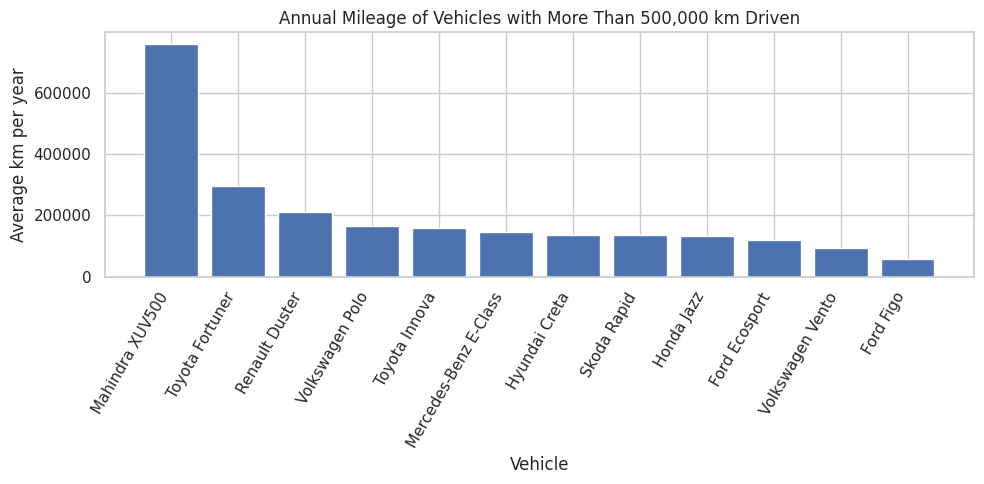

In [160]:
plt.figure(figsize=(10, 5))

plt.bar(extreme_km["car_name"], extreme_km["km_per_year"])

plt.xticks(rotation=60, ha="right")
plt.ylabel("Average km per year")
plt.xlabel("Vehicle")
plt.title("Annual Mileage of Vehicles with More Than 500,000 km Driven")

plt.tight_layout()
plt.show()

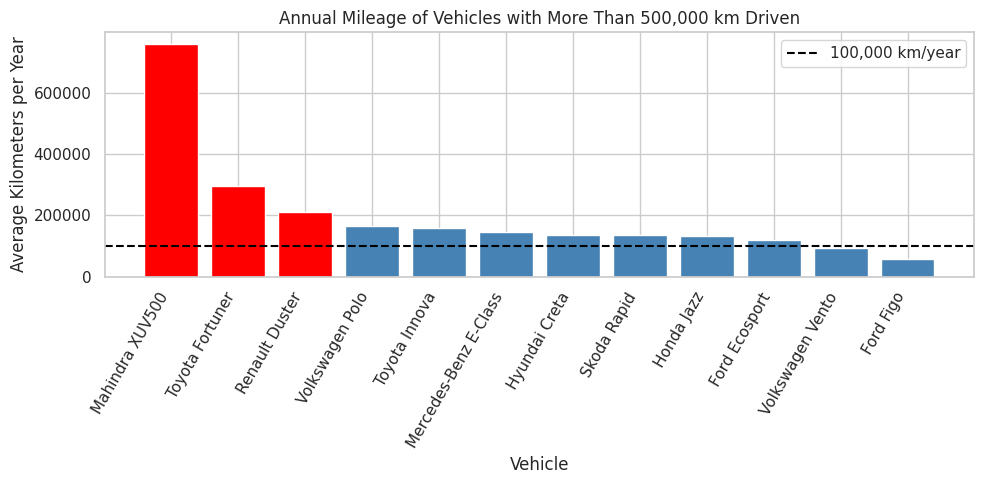

In [161]:
colors = [
    "red" if x > 200000 else "steelblue"
    for x in extreme_km["km_per_year"]
]

plt.figure(figsize=(10,5))

plt.bar(
    extreme_km["car_name"],
    extreme_km["km_per_year"],
    color=colors
)

plt.axhline(
    y=100000,
    color="black",
    linestyle="--",
    label="100,000 km/year"
)

plt.xticks(rotation=60, ha="right")

plt.ylabel("Average Kilometers per Year")
plt.xlabel("Vehicle")
plt.title("Annual Mileage of Vehicles with More Than 500,000 km Driven")

plt.legend()

plt.tight_layout()
plt.show()

### Findings

The annual mileage analysis shows that most high-mileage vehicles average between **50,000 and 160,000 km per year**, indicating intensive but potentially realistic usage.

Three vehicles exceed **200,000 km per year**, with the **Mahindra XUV500** reaching approximately **760,000 km per year**. Such values are highly unusual and may indicate data entry errors or exceptional fleet/commercial usage.

Since the dataset provides no additional information to verify these records, they were retained to preserve the integrity of the original data.

### Outlier Treatment Decision

The dataset contains several extreme mileage values. After investigation, some records showed unrealistic annual mileage values (>200,000 km/year), suggesting possible data entry errors.

These observations were removed because they could introduce unrealistic patterns and negatively affect regression performance.

For the remaining mileage distribution, logarithmic transformation was applied to reduce skewness.

In [183]:
import numpy as np

df["km_per_year"] = np.where(
    df["vehicle_age"] > 0,
    df["km_driven"] / df["vehicle_age"],
    df["km_driven"]
)

In [184]:
df = df[df["km_per_year"] <= 200000].copy()

In [185]:
df["log_km_driven"] = np.log1p(df["km_driven"])

In [186]:
df["km_driven"].describe()

count    1.540800e+04
mean     5.528723e+04
std      4.117511e+04
min      1.000000e+02
25%      3.000000e+04
50%      5.000000e+04
75%      7.000000e+04
max      1.325000e+06
Name: km_driven, dtype: float64

In [187]:
df[["km_driven", "km_per_year", "log_km_driven"]].describe()

,km_driven,km_per_year,log_km_driven
count,1.540800e+04,15408.000000,15408.000000
mean,5.528723e+04,9778.028146,10.675826
std,4.117511e+04,6829.768272,0.773201
min,1.000000e+02,100.000000,4.615121
25%,3.000000e+04,5833.333333,10.308986
50%,5.000000e+04,8428.571429,10.819798
75%,7.000000e+04,12167.437500,11.156265
max,1.325000e+06,164000.000000,14.096924


In [188]:
df.sort_values(
    "km_per_year",
    ascending=False
)[
    ["car_name", "vehicle_age", "km_driven", "km_per_year", "selling_price"]
].head(10)

,car_name,vehicle_age,km_driven,km_per_year,selling_price
11615,Volkswagen Polo,5,820000,164000.000000,695000
8772,Toyota Innova,6,950000,158333.333333,950000
12325,Renault Duster,1,150000,150000.000000,600000
11903,Mercedes-Benz E-Class,9,1325000,147222.222222,1350000
10838,Hyundai Creta,6,825000,137500.000000,825000
9170,Skoda Rapid,5,675000,135000.000000,675000
10384,Honda Jazz,4,525000,131250.000000,525000
7323,Ford Ecosport,6,720000,120000.000000,675000
10180,Maruti Ciaz,4,480000,120000.000000,725000
13843,Maruti Ciaz,4,450003,112500.750000,690000


### Mileage Outlier Treatment

After calculating annual mileage (`km_per_year`), several extreme usage cases were identified. Records exceeding 200,000 km/year were considered unrealistic and removed.

Remaining high-mileage vehicles were retained because they represent possible real-world scenarios such as commercial, taxi, fleet, or chauffeur usage. Removing these observations could reduce the model's ability to generalize to high-usage vehicles.

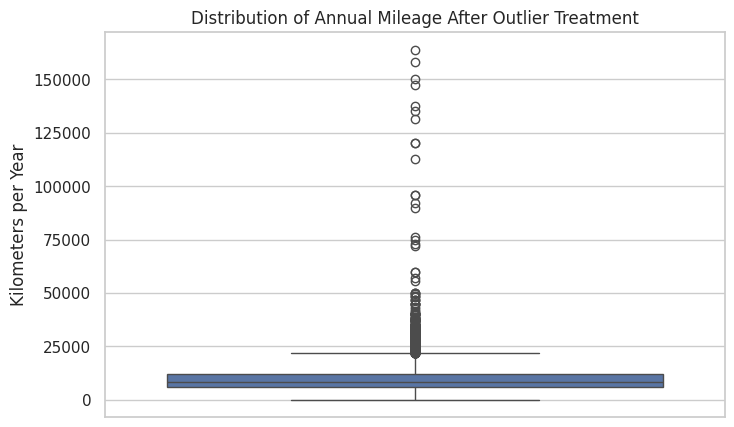

In [189]:
plt.figure(figsize=(8,5))

sns.boxplot(
    y=df["km_per_year"]
)

plt.title("Distribution of Annual Mileage After Outlier Treatment")
plt.ylabel("Kilometers per Year")

plt.show()

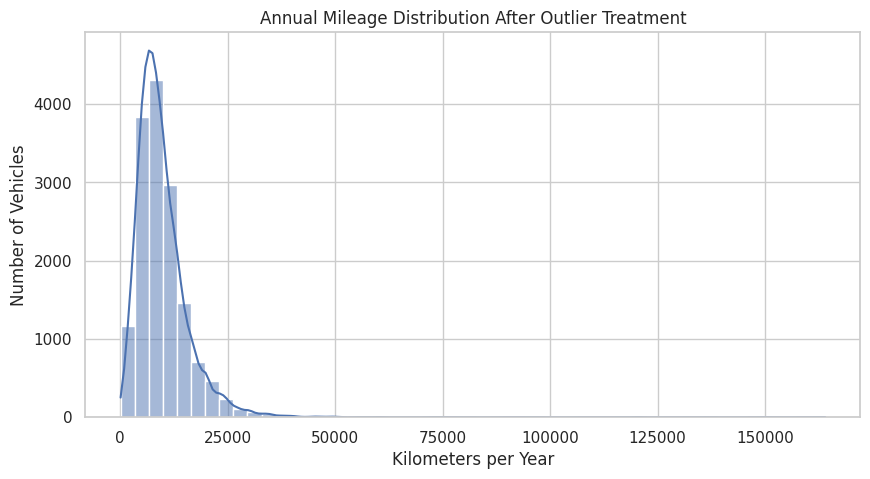

In [190]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["km_per_year"],
    bins=50,
    kde=True
)

plt.title("Annual Mileage Distribution After Outlier Treatment")
plt.xlabel("Kilometers per Year")
plt.ylabel("Number of Vehicles")

plt.show()

In [191]:
high_mileage_after_cleaning = df[df["km_per_year"] > 50000].sort_values(
    "km_per_year",
    ascending=False
).head(15)

In [192]:
high_mileage_after_cleaning["km_per_year"]

11615    164000.000000
8772     158333.333333
12325    150000.000000
11903    147222.222222
10838    137500.000000
9170     135000.000000
10384    131250.000000
7323     120000.000000
10180    120000.000000
13843    112500.750000
10589     96000.000000
8341      95800.000000
6712      92222.222222
15158     90000.000000
14032     76165.000000
Name: km_per_year, dtype: float64

In [196]:
# colors = [
#     "darkorange" if x > 100000 else "steelblue"
#     for x in high_km["km_per_year"]
# ]

# plt.figure(figsize=(10,5))

# plt.bar(
#     high_km["car_name"],
#     high_km["km_per_year"],
#     color=colors
# )

# plt.axhline(
#     y=100000,
#     color="black",
#     linestyle="--",
#     label="100,000 km/year"
# )

# plt.xticks(rotation=60, ha="right")

# plt.ylabel("Average Kilometers per Year")
# plt.xlabel("Vehicle")

# plt.title(
#     "High Annual Mileage Vehicles After Outlier Treatment"
# )

# plt.legend()

# plt.tight_layout()

# plt.show()

# Exploratory Data Analysis (EDA)

# Target Variable Analysis: Selling Price


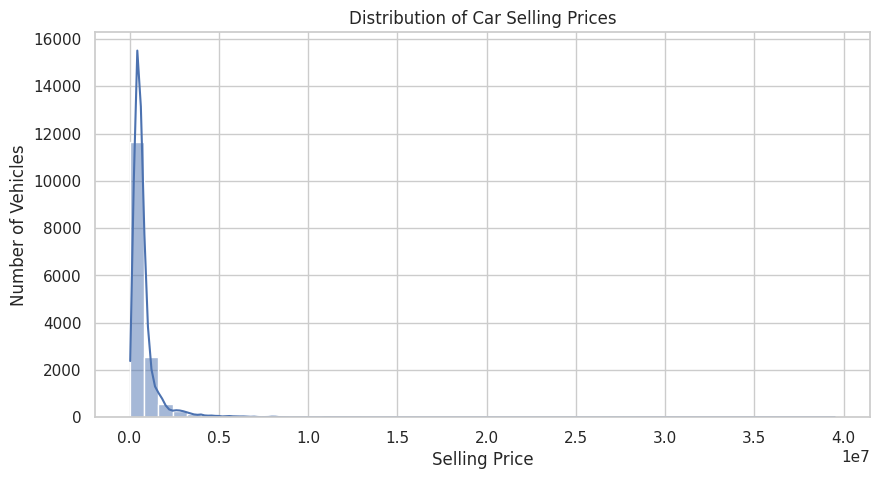

In [197]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["selling_price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Vehicles")

plt.show()

In [198]:
df["selling_price"].skew()

np.float64(10.051340954770604)

### Selling Price Skewness Analysis

The selling price feature has a strong positive skewness value (~10.05), indicating that the distribution is highly right-skewed.

Most vehicles belong to the lower and middle price ranges, while a small number of high-value vehicles create a long upper tail.

Since extreme price values may influence regression models, a logarithmic transformation can be considered to reduce skewness and improve model stability.

In [199]:
df["log_selling_price"] = np.log1p(df["selling_price"])

In [200]:
df["log_selling_price"].skew()

np.float64(0.568610076385283)

## Selling Price Transformation

The original selling price distribution showed strong positive skewness (10.05), caused by a small number of high-value vehicles.

A logarithmic transformation was applied using `log1p()` to reduce the impact of extreme prices.

After transformation, skewness decreased to approximately 0.57, resulting in a more balanced distribution that can improve model stability, especially for regression algorithms sensitive to feature distribution.

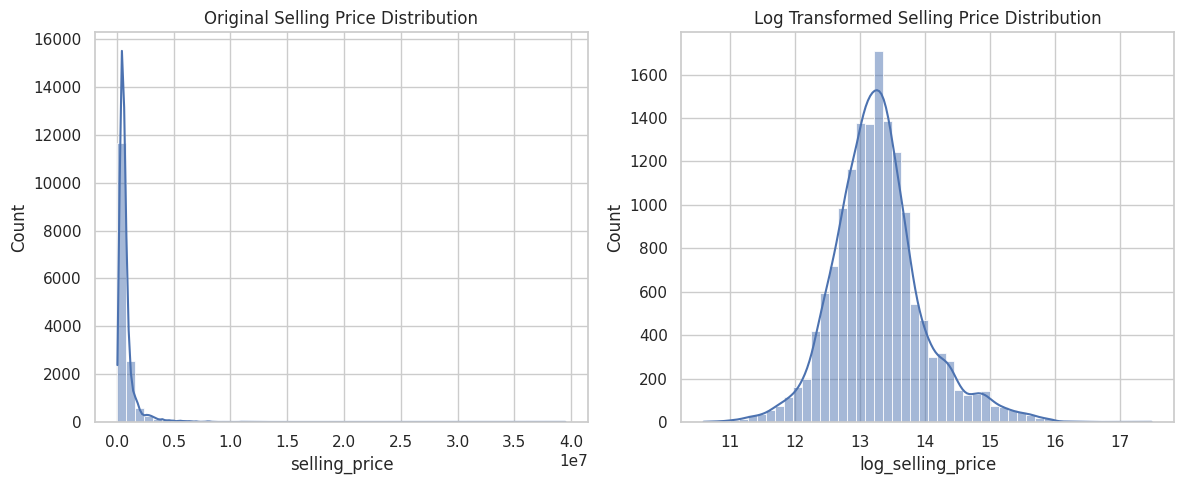

In [201]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

sns.histplot(
    df["selling_price"],
    bins=50,
    kde=True
)

plt.title("Original Selling Price Distribution")


plt.subplot(1,2,2)

sns.histplot(
    df["log_selling_price"],
    bins=50,
    kde=True
)

plt.title("Log Transformed Selling Price Distribution")


plt.tight_layout()
plt.show()

In [202]:
df["log_selling_price"].describe()

count    15408.000000
mean        13.279390
std          0.686700
min         10.596660
25%         12.861001
50%         13.228525
75%         13.623140
max         17.491811
Name: log_selling_price, dtype: float64

# EDA Step 2: Numerical Feature Analysis

In [203]:
numeric_features = [
    "vehicle_age",
    "km_driven",
    "km_per_year",
    "log_km_driven",
    "engine",
    "max_power",
    "seats"
]

In [204]:
df[numeric_features].describe()

,vehicle_age,km_driven,km_per_year,log_km_driven,engine,max_power,seats
count,15408.000000,1.540800e+04,15408.000000,15408.000000,15408.000000,15408.000000,15408.000000
mean,6.036799,5.528723e+04,9778.028146,10.675826,1485.932048,100.581989,5.325935
std,3.013353,4.117511e+04,6829.768272,0.773201,521.027187,42.971651,0.805203
min,0.000000,1.000000e+02,100.000000,4.615121,793.000000,38.400000,2.000000
25%,4.000000,3.000000e+04,5833.333333,10.308986,1197.000000,74.000000,5.000000
50%,6.000000,5.000000e+04,8428.571429,10.819798,1248.000000,88.500000,5.000000
75%,8.000000,7.000000e+04,12167.437500,11.156265,1582.000000,117.300000,5.000000
max,29.000000,1.325000e+06,164000.000000,14.096924,6592.000000,626.000000,9.000000


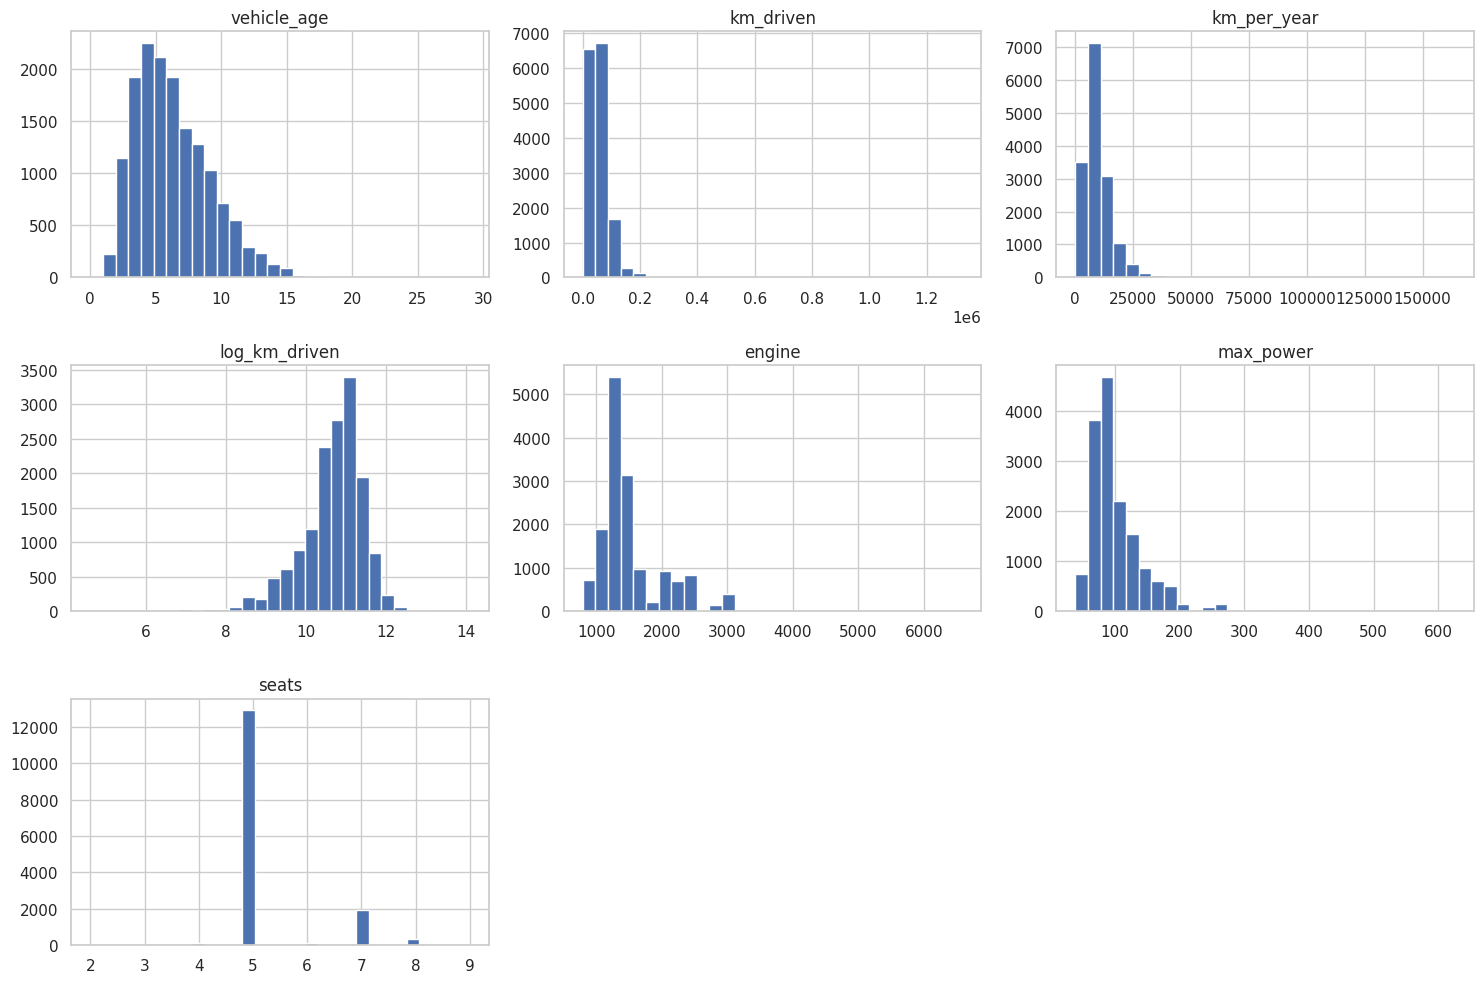

In [205]:
df[numeric_features].hist(
    figsize=(15,10),
    bins=30
)

plt.tight_layout()
plt.show()

## Numerical Feature Analysis Summary

- Most vehicles in the dataset are relatively recent used cars with an average age of approximately 6 years.
- Mileage-related features (`km_driven` and `km_per_year`) show right-skewed distributions due to a small number of high-usage vehicles.
- Log transformation reduced the effect of extreme mileage values.
- Engine size and maximum power are positively skewed because premium vehicles introduce higher values.
- Seat count is dominated by five-seat vehicles, reflecting the common passenger car category.
- The numerical features show realistic distributions after cleaning and feature engineering.

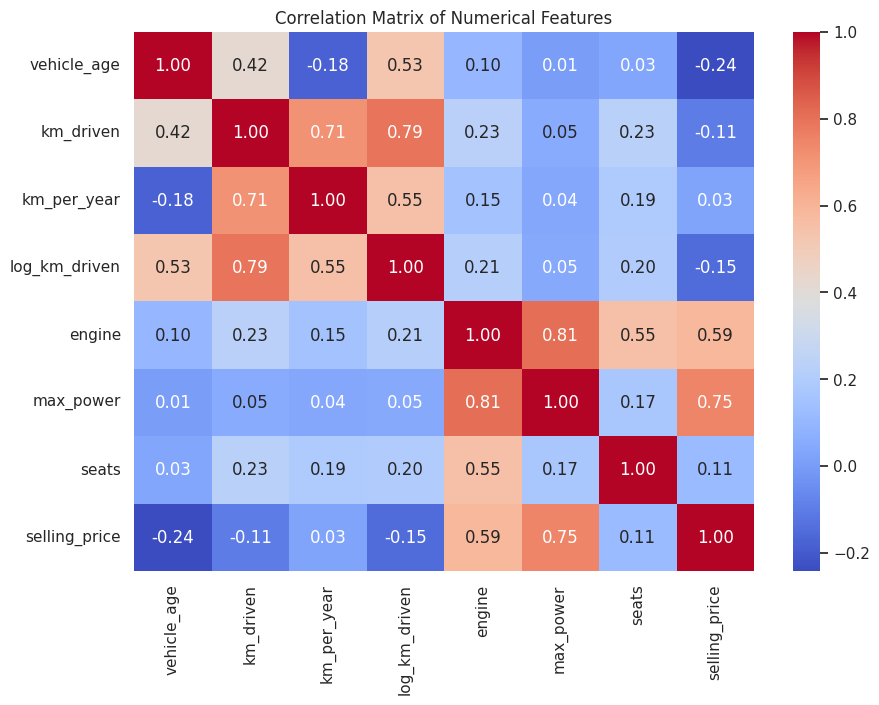

In [206]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df[numeric_features + ["selling_price"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")

plt.show()

# Step 2: Feature vs Target Analysis (Numerical Features)

The purpose:

Correlation gives you a number. Feature vs Target plots help me understand the actual relationship and detect patterns, outliers, and non-linear behavior.

In [207]:
target = 'selling_price'

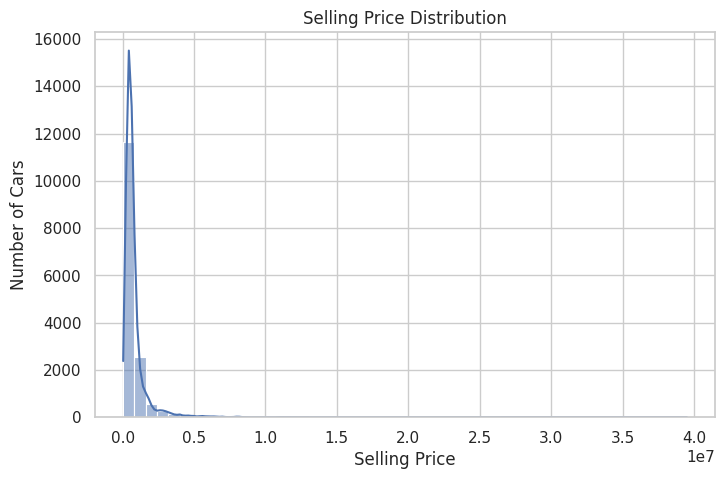

In [208]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['selling_price'],
  bins=50,
kde=True
)

plt.title("Selling Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

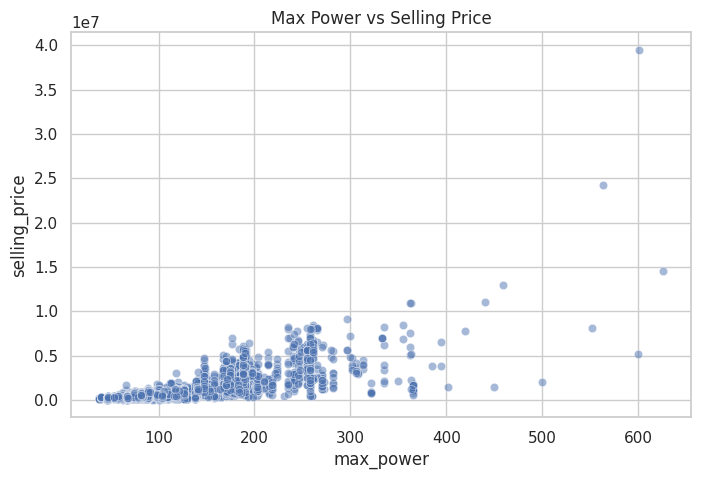

In [210]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='max_power',
    y='selling_price',
    data=df,
    alpha=0.5
)

plt.title("Max Power vs Selling Price")

plt.show()

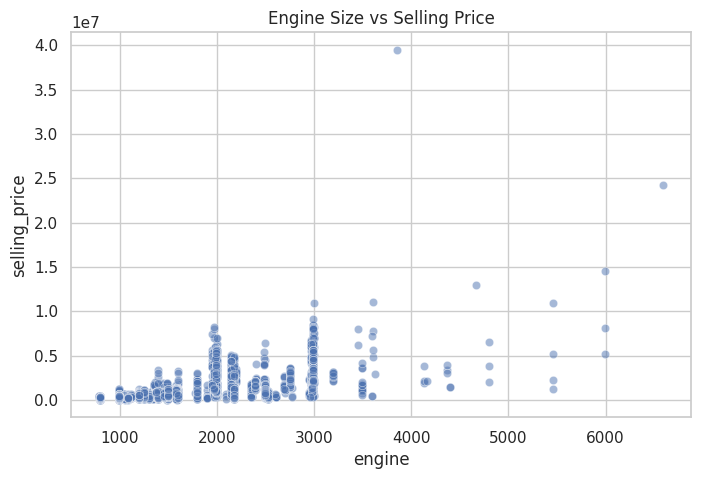

In [211]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='engine',
    y='selling_price',
    data=df,
    alpha=0.5
)

plt.title("Engine Size vs Selling Price")

plt.show()

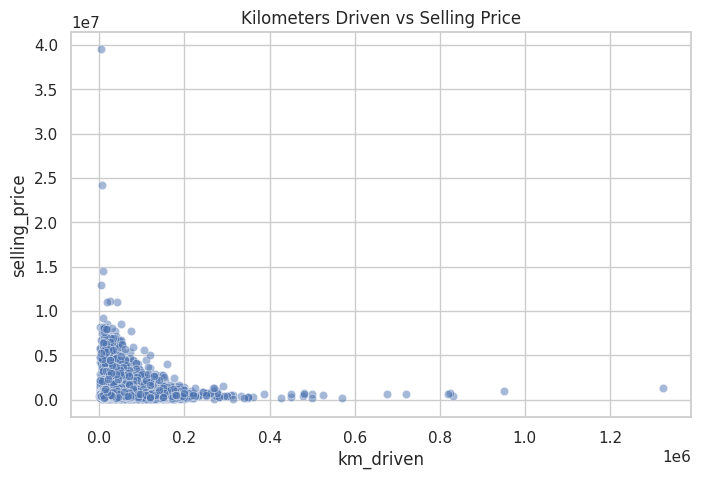

In [212]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='km_driven',
    y='selling_price',
    data=df,
    alpha=0.5
)

plt.title("Kilometers Driven vs Selling Price")

plt.show()

#  Regression Plot

A regression line helps visualize the general direction.

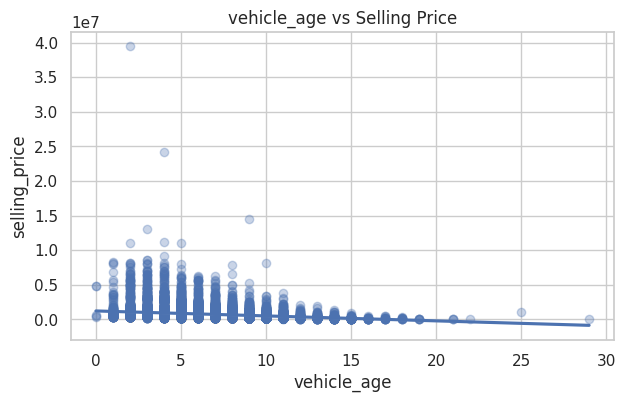

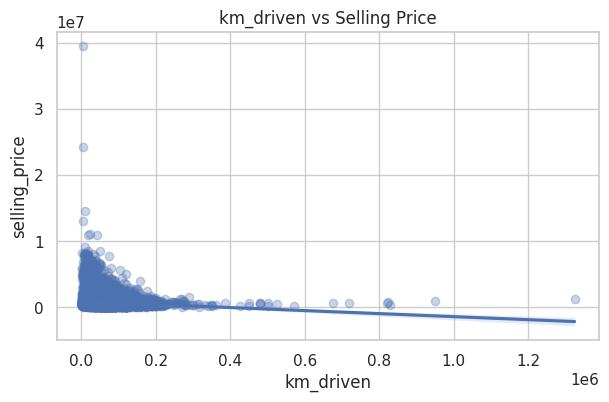

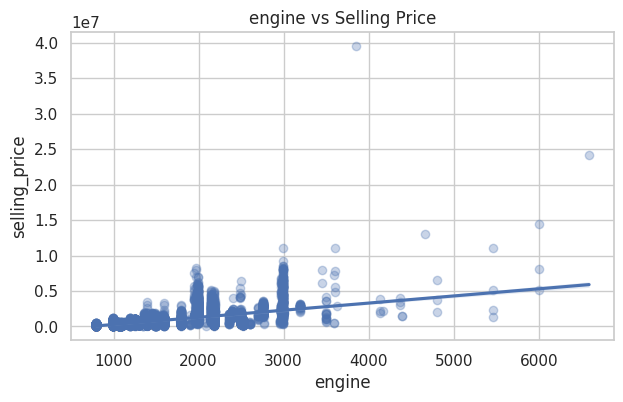

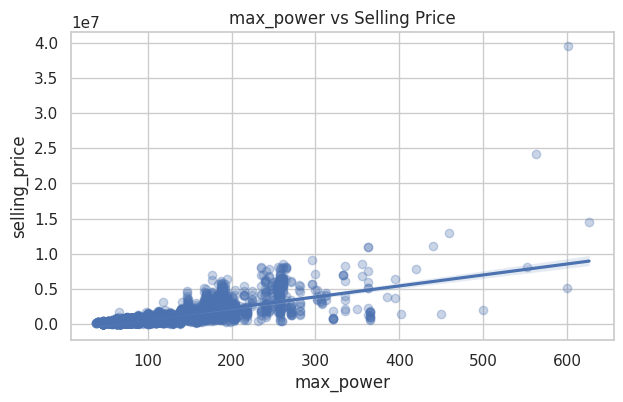

In [213]:
features = [
    'vehicle_age',
    'km_driven',
    'engine',
    'max_power'
]


for feature in features:

    plt.figure(figsize=(7,4))

    sns.regplot(
        x=feature,
        y='selling_price',
        data=df,
        scatter_kws={'alpha':0.3}
    )

    plt.title(f"{feature} vs Selling Price")

    plt.show()

## Feature vs Target Analysis Findings

- Selling price distribution is skewed, with many vehicles concentrated in lower price ranges and fewer expensive vehicles.
- Vehicle age shows a negative relationship with selling price, confirming vehicle depreciation.
- Maximum power has the strongest relationship with price, where higher-power vehicles generally have higher values.
- Engine size positively affects price because larger engines are usually associated with premium vehicles.
- Mileage has a weaker relationship with price because other factors such as brand and vehicle condition influence value.
- Some relationships may be nonlinear, so machine learning models can capture patterns that correlation cannot.

# Step 3: Categorical Feature Analysis
Why do we analyze categorical features?

The correlation matrix only works with numerical features.

# Analyze Fuel Type vs Selling Price

In [214]:
df.columns

Index(['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price', 'km_per_year', 'log_km_driven',
       'log_selling_price'],
      dtype='object')

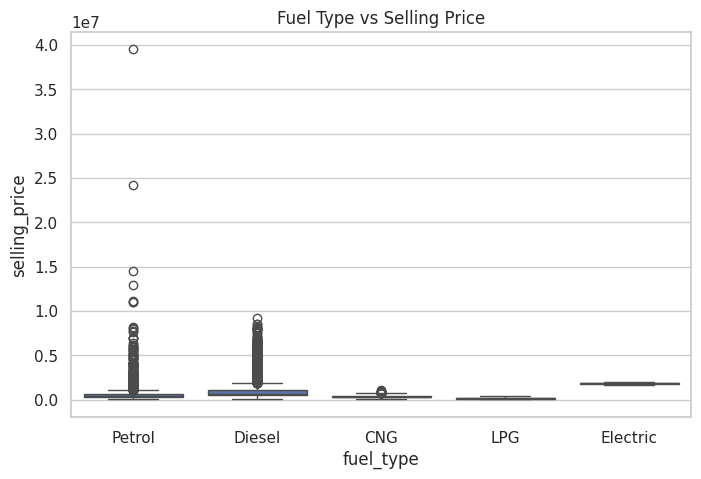

In [215]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='fuel_type',
    y='selling_price',
    data=df
)

plt.title("Fuel Type vs Selling Price")
plt.show()

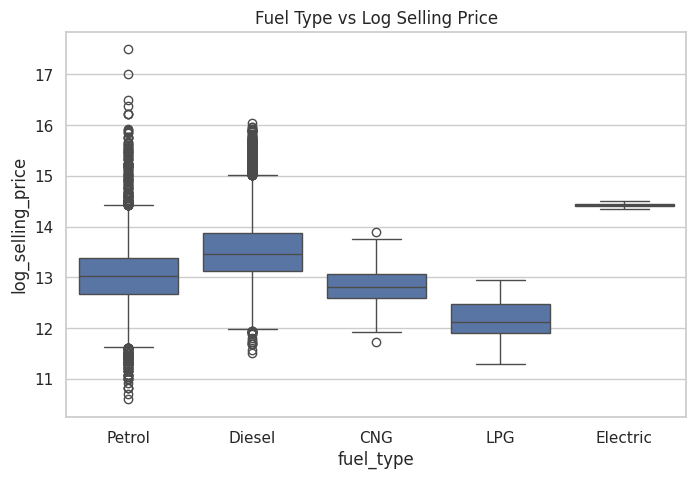

In [216]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='fuel_type',
    y='log_selling_price',
    data=df
)

plt.title("Fuel Type vs Log Selling Price")

plt.show()

## Fuel Type vs Selling Price

- Fuel type shows differences in vehicle price distribution.
- Diesel vehicles generally have higher selling prices compared with other fuel types, possibly because diesel cars are common among SUVs and higher-value vehicles.
- Petrol vehicles cover a wide range of prices, including both budget and premium segments.
- CNG and LPG vehicles are mainly concentrated in lower price ranges.
- Electric vehicles appear expensive, but the category has fewer observations, so conclusions should be made carefully.
- Due to extreme price outliers, log-transformed selling price was considered for better visualization.

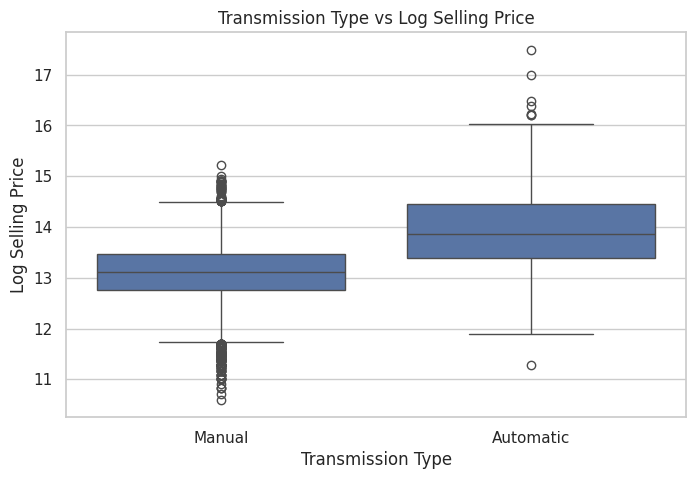

In [217]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='transmission_type',
    y='log_selling_price',
    data=df
)

plt.title("Transmission Type vs Log Selling Price")
plt.xlabel("Transmission Type")
plt.ylabel("Log Selling Price")

plt.show()

In [218]:
df.groupby('transmission_type')['selling_price'].describe()

,count,mean,std,min,25%,50%,75%,max
transmission_type,,,,,,,,
Automatic,3186.0,1.579557e+06,1.631571e+06,80000.0,649000.0,1057000.0,1900000.0,39500000.0
Manual,12222.0,5.650210e+05,3.179555e+05,40000.0,350000.0,500000.0,700000.0,4050000.0


In [219]:
df['transmission_type'].value_counts()

transmission_type
Manual       12222
Automatic     3186
Name: count, dtype: int64

## Transmission Type vs Selling Price

- Transmission type shows a strong relationship with vehicle price.
- Automatic vehicles have a significantly higher median selling price (1.057M) compared with manual vehicles (500K).
- Automatic vehicles also show a wider price distribution, indicating that they exist more frequently in higher-priced vehicle segments.
- The difference may be explained by automatic transmissions being more common in newer, luxury, and premium vehicles.
- Although automatic cars represent fewer samples, the category contains enough observations to provide useful predictive information.
- Transmission type should be kept as a feature for the machine learning model.

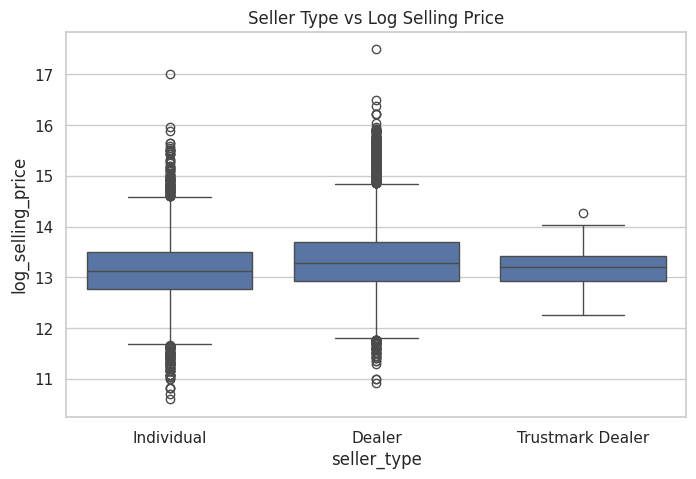

In [220]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='seller_type',
    y='log_selling_price',
    data=df
)

plt.title("Seller Type vs Log Selling Price")

plt.show()

In [221]:
df.groupby('seller_type')['selling_price'].describe()

,count,mean,std,min,25%,50%,75%,max
seller_type,,,,,,,,
Dealer,9536.0,872263.527685,1.024169e+06,55000.0,414000.0,591000.0,890000.0,39500000.0
Individual,5699.0,617880.483418,6.022878e+05,40000.0,350000.0,507000.0,725000.0,24200000.0
Trustmark Dealer,173.0,571959.537572,2.262035e+05,210000.0,410000.0,540000.0,675000.0,1575000.0


In [222]:
df['seller_type'].value_counts()

seller_type
Dealer              9536
Individual          5699
Trustmark Dealer     173
Name: count, dtype: int64

## Seller Type vs Selling Price

- Seller type shows some differences in vehicle price distribution.
- Dealer vehicles have the highest median selling price (591K), followed by Trustmark Dealer (540K) and Individual sellers (507K).
- Dealer vehicles also show a wider price range, indicating that dealerships sell vehicles across different market segments.
- The difference between seller categories is smaller compared with other features such as transmission type.
- Trustmark Dealer contains a limited number of observations, so its impact should be interpreted carefully.
- Seller type may provide useful predictive information and should be included as a model feature.

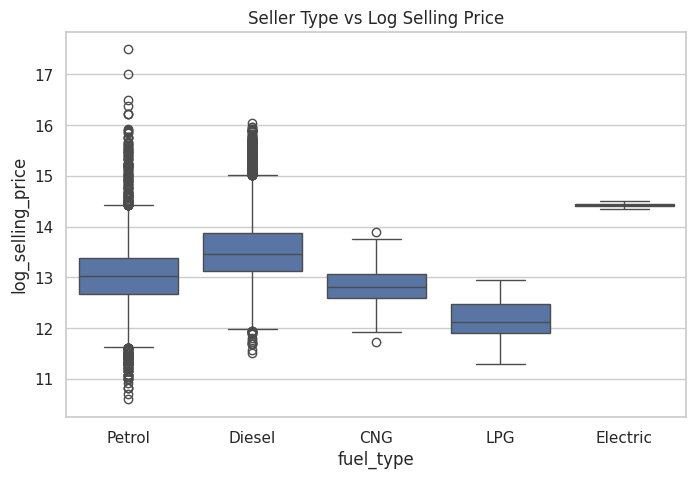

In [223]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='fuel_type',
    y='log_selling_price',
    data=df
)

plt.title("Seller Type vs Log Selling Price")

plt.show()

In [224]:
df.groupby('fuel_type')['selling_price'].describe()

,count,mean,std,min,25%,50%,75%,max
fuel_type,,,,,,,,
CNG,301.0,4.176877e+05,179483.319973,125000.0,295000.0,370000.0,475000.0,1080000.0
Diesel,7416.0,1.000210e+06,948207.294590,100000.0,500000.0,700000.0,1070000.0,9200000.0
Electric,4.0,1.853500e+06,123121.890824,1699000.0,1812250.0,1857500.0,1898750.0,2000000.0
LPG,44.0,2.062727e+05,83080.337594,80000.0,147250.0,182500.0,260000.0,420000.0
Petrol,7643.0,5.728619e+05,800148.637057,40000.0,320000.0,460000.0,645000.0,39500000.0


In [225]:
df['fuel_type'].value_counts()

fuel_type
Petrol      7643
Diesel      7416
CNG          301
LPG           44
Electric       4
Name: count, dtype: int64

## Fuel Type vs Selling Price

- Fuel type shows a clear relationship with vehicle selling price.
- Diesel vehicles have the highest median price among the major fuel categories (700K), followed by petrol vehicles (460K).
- Diesel vehicles generally appear in higher-priced segments, possibly because they are more common in SUVs and larger vehicles.
- CNG and LPG vehicles are concentrated in lower price ranges.
- Electric vehicles show a high median price, but the category contains only four observations, so conclusions are unreliable.
- Fuel type should be kept as a feature because it provides useful information for predicting vehicle prices.

In [226]:
df.groupby('brand')['selling_price'].describe()

,count,mean,std,min,25%,50%,75%,max
brand,,,,,,,,
Audi,192.0,1.966865e+06,1.017379e+06,750000.0,1336250.0,1700000.0,2200000.0,6800000.0
BMW,439.0,2.693827e+06,1.672992e+06,465000.0,1399000.0,2300000.0,3472500.0,8500000.0
Bentley,3.0,9.266667e+06,4.758501e+06,5200000.0,6650000.0,8100000.0,11300000.0,14500000.0
Datsun,170.0,3.205176e+05,8.806925e+04,170000.0,256000.0,300000.0,350000.0,650000.0
Ferrari,1.0,3.950000e+07,NaN,39500000.0,39500000.0,39500000.0,39500000.0,39500000.0
Force,1.0,7.000000e+05,NaN,700000.0,700000.0,700000.0,700000.0,700000.0
Ford,790.0,6.452241e+05,4.987389e+05,130000.0,364250.0,570000.0,738750.0,3200000.0
Honda,1485.0,6.177569e+05,2.903125e+05,50000.0,425000.0,590000.0,754000.0,3200000.0
Hyundai,2982.0,5.761539e+05,2.886559e+05,60000.0,375000.0,525000.0,700000.0,2600000.0


In [227]:
df.groupby('model')['selling_price'].median().sort_values(ascending=False)

model
GTC4Lusso      39500000.0
Ghost          24200000.0
Continental     8100000.0
RX              7100000.0
GLS             6950000.0
                  ...    
Figo             280000.0
i10              275000.0
RediGO           270000.0
Alto             250000.0
Santro           240000.0
Name: selling_price, Length: 120, dtype: float64

## Brand and Model vs Selling Price

- Brand and model exhibit a strong relationship with vehicle selling price.
- Luxury brands such as Porsche, Lexus, Land Rover, BMW, Mercedes-Benz, and Audi have substantially higher median selling prices than economy brands such as Maruti, Hyundai, Renault, and Datsun.
- Individual vehicle models also show considerable variation in selling price, reflecting differences in market segment, engine specifications, features, and brand positioning.
- Some luxury brands (e.g., Ferrari, Rolls-Royce, Bentley, and Maserati) contain very few observations, so conclusions for these categories should be interpreted cautiously.
- Overall, both brand and model provide valuable predictive information and should be retained as features for the machine learning model.

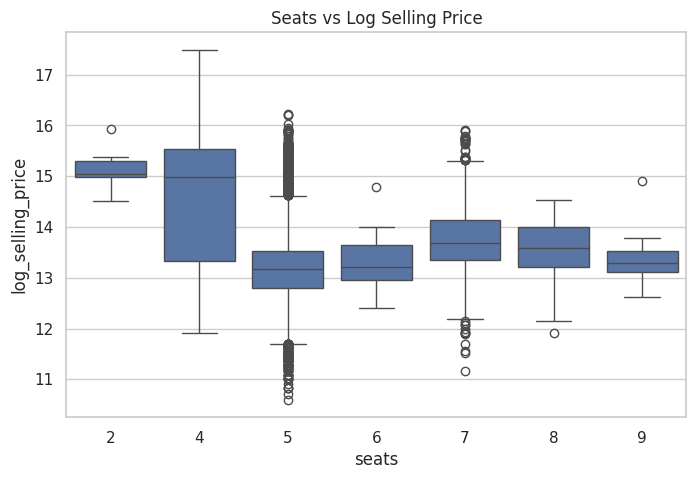

In [228]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='seats',
    y='log_selling_price',
    data=df
)

plt.title("Seats vs Log Selling Price")

plt.show()

In [229]:
corr = df.select_dtypes(include='number').corr()

corr['log_selling_price'].sort_values(ascending=False)

log_selling_price    1.000000
selling_price        0.784819
max_power            0.758553
engine               0.653724
seats                0.229802
km_per_year          0.144097
km_driven           -0.128442
log_km_driven       -0.175697
mileage             -0.301704
vehicle_age         -0.485176
Name: log_selling_price, dtype: float64

## Exploratory Data Analysis Summary

- The target variable was highly right-skewed; therefore, a logarithmic transformation was applied to stabilize its distribution.
- Numerical analysis showed that maximum engine power and engine capacity have strong positive correlations with selling price, while vehicle age has a moderate negative correlation due to depreciation.
- Mileage and fuel efficiency exhibit weaker negative relationships with selling price, suggesting that they influence price but are not the primary determinants.
- Categorical variables such as brand, model, transmission type, fuel type, and seller type also showed clear differences in price distributions.
- Premium brands and luxury models consistently command higher prices than economy brands and models.
- Overall, the dataset contains meaningful numerical and categorical predictors, making it well suited for machine learning models capable of handling mixed feature types.

# Data Preprocessing

In [230]:
X = df.drop(columns=['selling_price', 'log_selling_price'])
y = df['log_selling_price']

In [231]:
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']

Numerical Features:
['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'km_per_year', 'log_km_driven']


In [232]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [233]:
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (12326, 14)
Testing set: (3082, 14)


In [234]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

# Why use a pipeline?

Instead of manually:

Scaling
Encoding
Imputing

the pipeline guarantees that:

Training data is fitted correctly.
Test data uses the same transformations.
Future prediction data is processed identically.

# Model1 - LinearRegression

In [235]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [236]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats',
                                                   'km_per_year',
                                                   'log_km_driven']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['car_name', 'brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('regressor', LinearRegression())])

In [237]:
y_pred_lr = linear_model.predict(X_test)

In [238]:
lr_mae = mean_absolute_error(y_test, y_pred_lr)

lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

lr_r2 = r2_score(y_test, y_pred_lr)

print(f"MAE : {lr_mae:.4f}")
print(f"RMSE: {lr_rmse:.4f}")
print(f"R²  : {lr_r2:.4f}")

MAE : 0.1409
RMSE: 0.1887
R²  : 0.9269


In [239]:
lr_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_lr
})

lr_results.head(10)

,Actual,Predicted
10409,12.899222,12.801351
2760,12.301387,12.187373
3886,11.918397,12.011811
6007,13.122365,13.151309
13040,14.506656,14.342680
1714,13.560620,13.652667
10651,11.849405,11.771967
6500,12.971543,13.010280
2002,14.844773,14.634450
914,13.122365,12.972560


# Residual Analysis (Very Important)

In [240]:
residuals = y_test - y_pred_lr

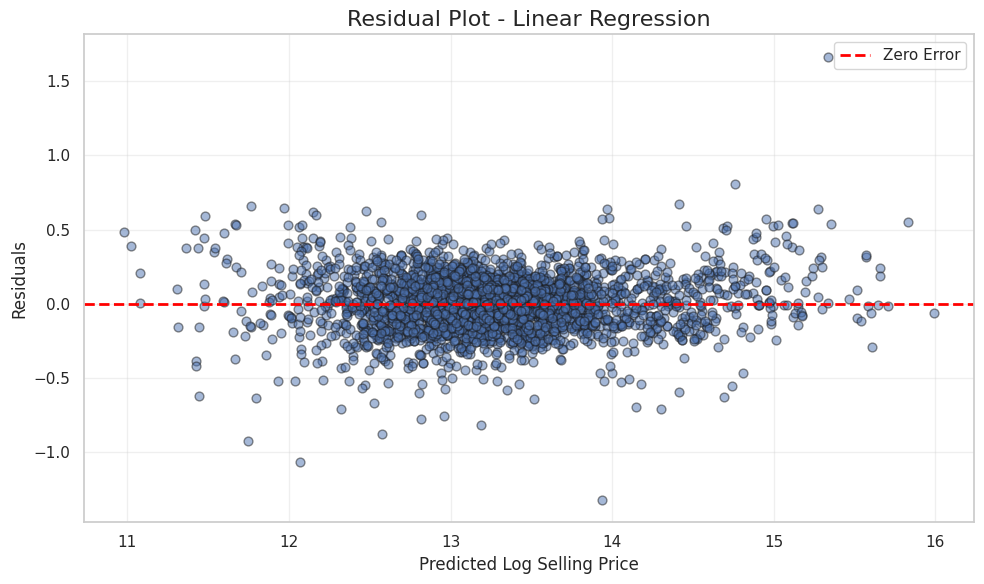

In [241]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_lr,
    residuals,
    alpha=0.5,
    edgecolor='k',
    s=40
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Zero Error'
)

plt.title('Residual Plot - Linear Regression', fontsize=16)
plt.xlabel('Predicted Log Selling Price', fontsize=12)
plt.ylabel('Residuals', fontsize=12)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

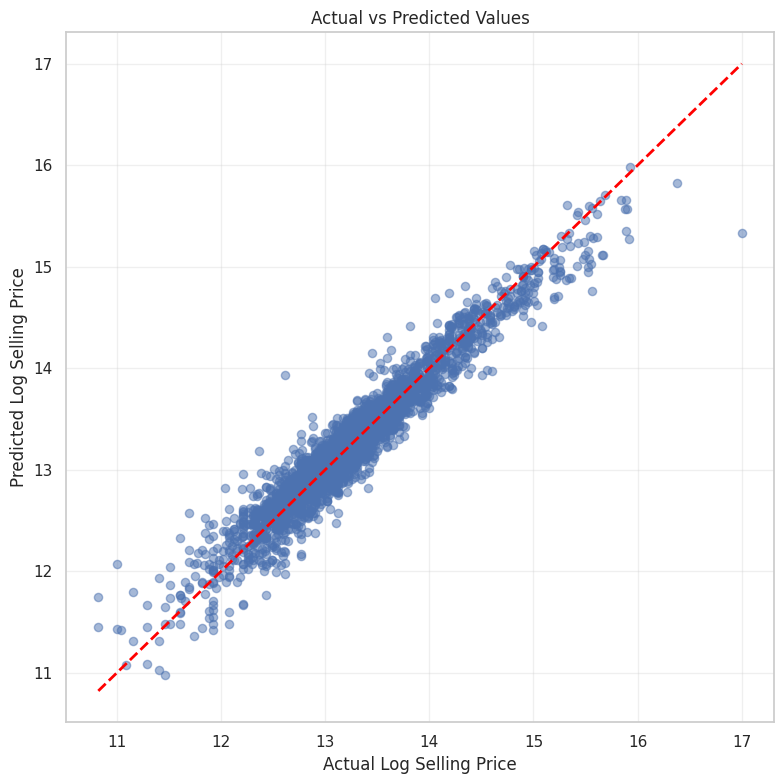

In [242]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.5,
    s=35
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Actual Log Selling Price")
plt.ylabel("Predicted Log Selling Price")

plt.title("Actual vs Predicted Values")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [243]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression'],
    'MAE': [lr_mae],
    'RMSE': [lr_rmse],
    'R2': [lr_r2]
})

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.140862,0.18866,0.926944


# Model 2 - the Decision Tree Model

In [244]:
decision_tree = DecisionTreeRegressor(
    random_state=42
)

In [245]:
decision_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', decision_tree)
])

In [246]:
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats',
                                                   'km_per_year',
                                                   'log_km_driven']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['car_name', 'brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('regressor', DecisionTreeRegressor(random_state=42))])

In [247]:
y_pred_dt = decision_tree_model.predict(X_test)

In [248]:
dt_mae = mean_absolute_error(y_test, y_pred_dt)

dt_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_dt)
)

dt_r2 = r2_score(y_test, y_pred_dt)

In [249]:
print("Decision Tree Performance")
print("-" * 30)

print(f"MAE : {dt_mae:.4f}")
print(f"RMSE: {dt_rmse:.4f}")
print(f"R²  : {dt_r2:.4f}")

Decision Tree Performance
------------------------------
MAE : 0.1644
RMSE: 0.2261
R²  : 0.8951


In [250]:
new_result = pd.DataFrame({
    "Model": ["Decision Tree"],
    "MAE": [dt_mae],
    "RMSE": [dt_rmse],
    "R2": [dt_r2]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.140862,0.188660,0.926944
1,Decision Tree,0.164371,0.226063,0.895104


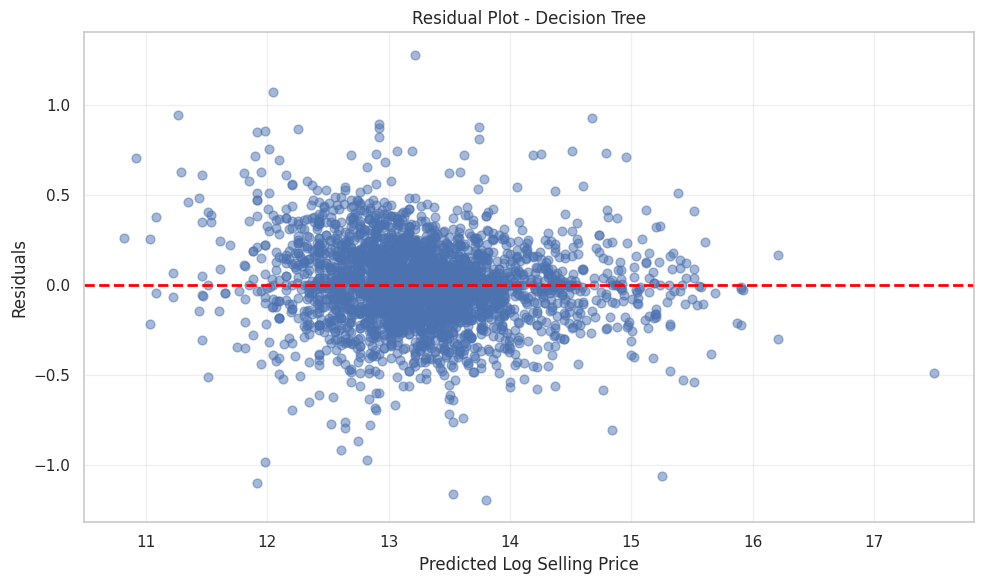

In [251]:
residuals_dt = y_test - y_pred_dt

plt.figure(figsize=(10,6))

plt.scatter(
    y_pred_dt,
    residuals_dt,
    alpha=0.5,
    s=40
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.title("Residual Plot - Decision Tree")

plt.xlabel("Predicted Log Selling Price")

plt.ylabel("Residuals")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

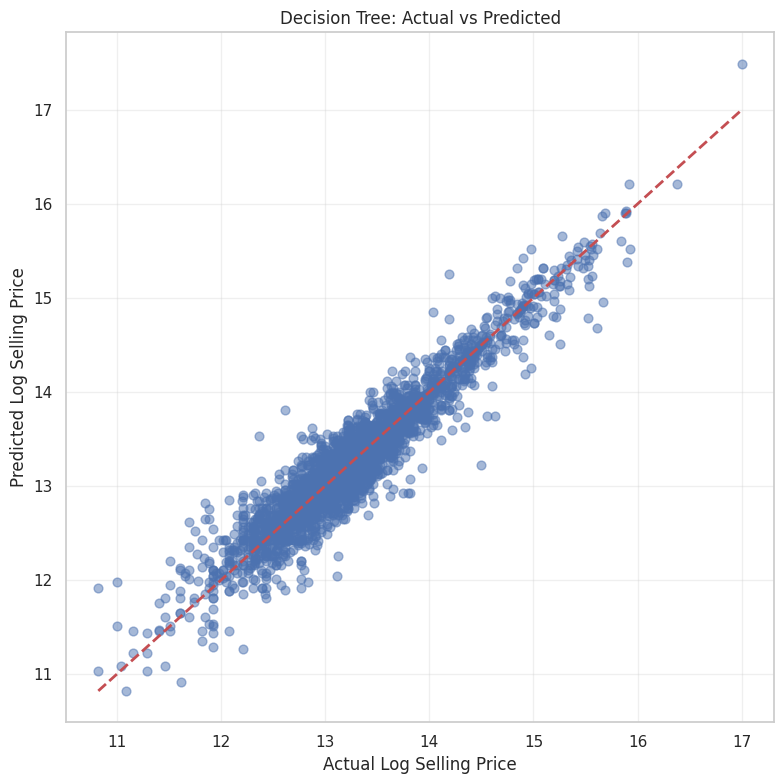

In [252]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    y_pred_dt,
    alpha=0.5,
    s=40
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Log Selling Price")

plt.ylabel("Predicted Log Selling Price")

plt.title("Decision Tree: Actual vs Predicted")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [253]:
small_tree = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)

small_tree.fit(X_train_processed, y_train)

DecisionTreeRegressor(max_depth=3, random_state=42)

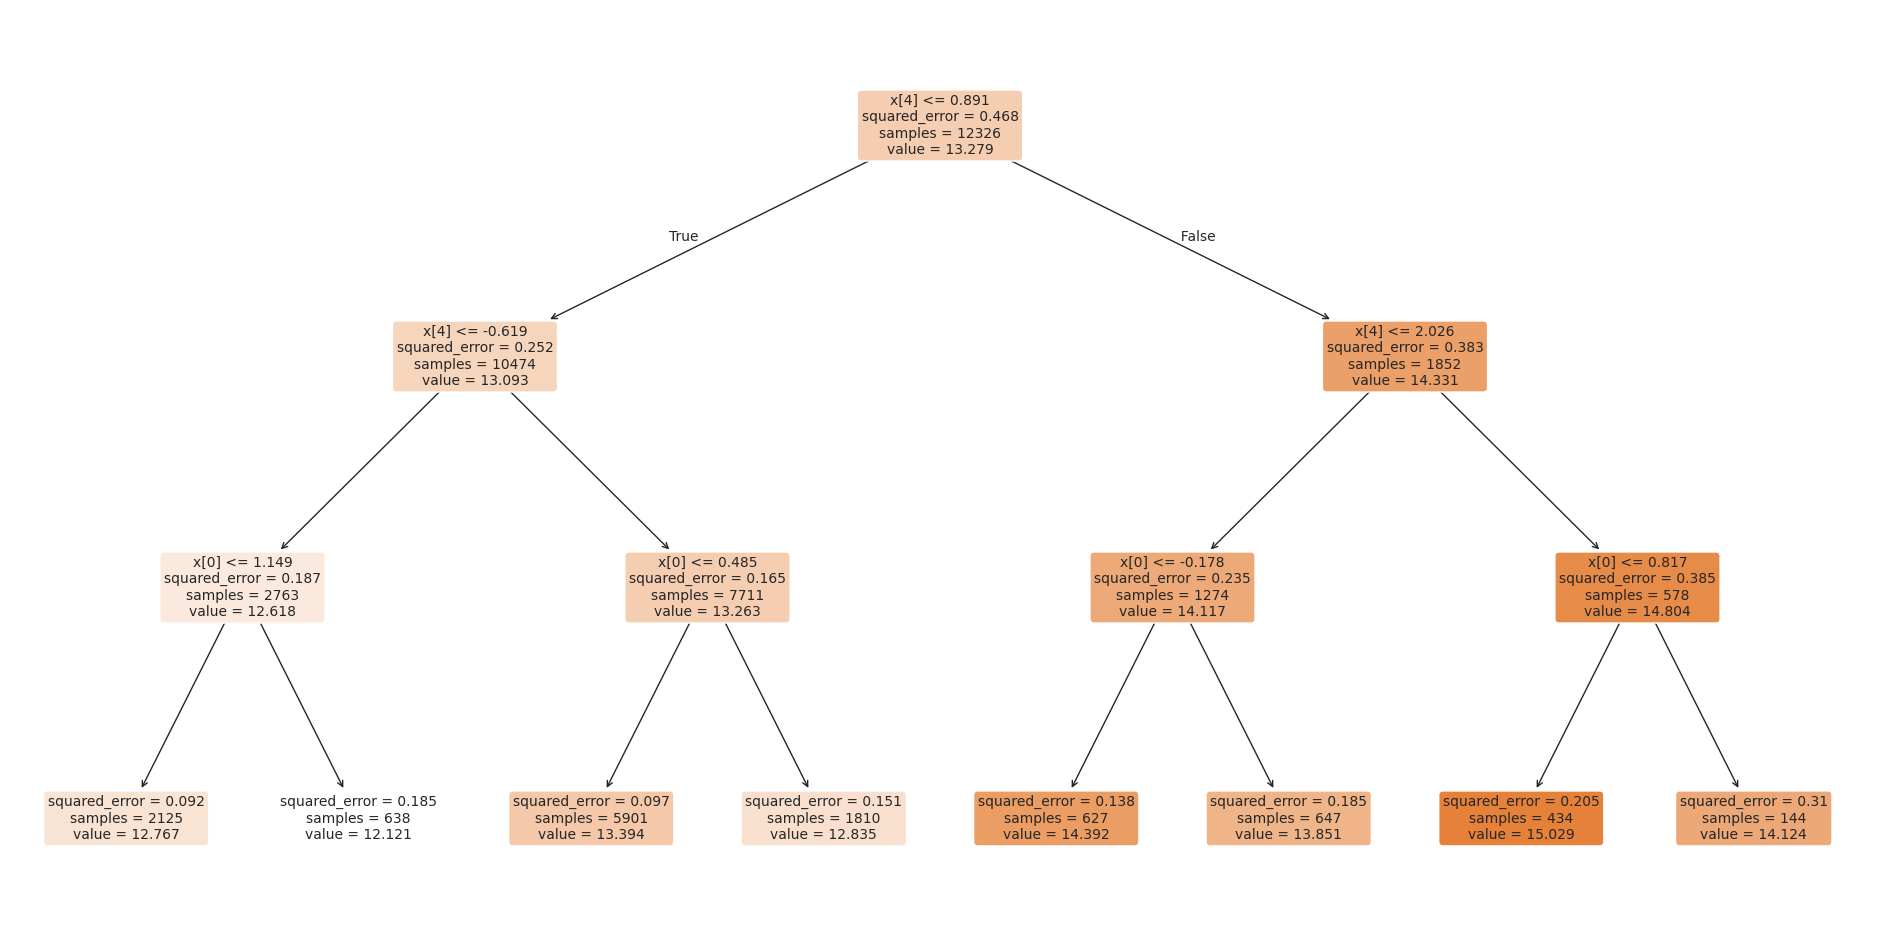

In [254]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24,12))

plot_tree(
    small_tree,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

# Model 3 — Random Forest Regressor

In [255]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', random_forest)
])

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

In [256]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

rf_r2 = r2_score(y_test, y_pred_rf)

In [257]:
print("Random Forest Performance")
print("-" * 35)

print(f"MAE : {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²  : {rf_r2:.4f}")

Random Forest Performance
-----------------------------------
MAE : 0.1291
RMSE: 0.1773
R²  : 0.9355


In [258]:
new_result = pd.DataFrame({
    "Model": ["Random Forest"],
    "MAE": [rf_mae],
    "RMSE": [rf_rmse],
    "R2": [rf_r2]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.140862,0.188660,0.926944
1,Decision Tree,0.164371,0.226063,0.895104
2,Random Forest,0.129078,0.177262,0.935504


# Model 4 - GradientBoostingRegressor

In [259]:
gradient_boosting = GradientBoostingRegressor(
    random_state=42
)

In [260]:
gradient_boosting_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', gradient_boosting)
])

In [261]:
gradient_boosting_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats',
                                                   'km_per_year',
                                                   'log_km_driven']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['car_name', 'brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('regressor', GradientBoostingRegressor(random_state=42))])

In [262]:
y_pred_gb = gradient_boosting_model.predict(X_test)

In [263]:
gb_mae = mean_absolute_error(y_test, y_pred_gb)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_gb)
)

gb_r2 = r2_score(y_test, y_pred_gb)

In [264]:
print("Gradient Boosting Performance")
print("-" * 35)

print(f"MAE : {gb_mae:.4f}")
print(f"RMSE: {gb_rmse:.4f}")
print(f"R²  : {gb_r2:.4f}")

Gradient Boosting Performance
-----------------------------------
MAE : 0.1426
RMSE: 0.1909
R²  : 0.9252


In [265]:
new_result = pd.DataFrame({
    "Model": ["Gradient Boosting"],
    "MAE": [gb_mae],
    "RMSE": [gb_rmse],
    "R2": [gb_r2]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.140862,0.188660,0.926944
1,Decision Tree,0.164371,0.226063,0.895104
2,Random Forest,0.129078,0.177262,0.935504
3,Gradient Boosting,0.142583,0.190871,0.925221


# Model 5 - XGBoost 

In [266]:
!pip install xgboost

In [267]:
from xgboost import XGBRegressor

# Create the XGBoost model
xgboost = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective='reg:squarederror'
)

# Create the pipeline
xgboost_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', xgboost)
])

In [268]:
xgboost_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats',
                                                   'km_per_year',
                                                   'log_km_driven']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneH...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=100, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [269]:
y_pred_xgb = xgboost_model.predict(X_test)

In [270]:
xgb_mae = mean_absolute_error(
    y_test,
    y_pred_xgb
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

xgb_r2 = r2_score(
    y_test,
    y_pred_xgb
)

In [271]:
print("XGBoost Performance")
print("-" * 35)

print(f"MAE : {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"R²  : {xgb_r2:.4f}")

XGBoost Performance
-----------------------------------
MAE : 0.1266
RMSE: 0.1706
R²  : 0.9402


In [272]:
new_result = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [xgb_mae],
    "RMSE": [xgb_rmse],
    "R2": [xgb_r2]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.140862,0.188660,0.926944
1,Decision Tree,0.164371,0.226063,0.895104
2,Random Forest,0.129078,0.177262,0.935504
3,Gradient Boosting,0.142583,0.190871,0.925221
4,XGBoost,0.126590,0.170634,0.940237


# Model 6- CatBoost

In [273]:
!pip install catboost

In [276]:
catboost = CatBoostRegressor(
    iterations=500,
    learning_rate=0.1,
    depth=6,
    random_state=42,
    verbose=0
)
catboost_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', catboost)
])

In [277]:
catboost_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', catboost)
])

In [278]:
catboost_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['vehicle_age', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power', 'seats',
                                                   'km_per_year',
                                                   'log_km_driven']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['car_name', 'brand', 'model',
                                                   'seller_type', 'fuel_type',
                                                   'transmission_type'])])),
                ('regressor',
                 CatBoostRegressor(depth=6, iterations=500, learning_rate=0.1, loss_function='RMSE', random_state=42, verbose=0))])

In [279]:
y_pred_cb = catboost_model.predict(X_test)

In [280]:
cb_mae = mean_absolute_error(
    y_test,
    y_pred_cb
)

cb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_cb
    )
)

cb_r2 = r2_score(
    y_test,
    y_pred_cb
)

In [281]:
print("CatBoost Performance")
print("-"*35)

print(f"MAE : {cb_mae:.4f}")
print(f"RMSE: {cb_rmse:.4f}")
print(f"R²  : {cb_r2:.4f}")

CatBoost Performance
-----------------------------------
MAE : 0.1220
RMSE: 0.1645
R²  : 0.9445


In [282]:

new_result = pd.DataFrame({
    "Model": ["CatBoost"],
    "MAE": [cb_mae],
    "RMSE": [cb_rmse],
    "R2": [cb_r2]
})

model_results = pd.concat(
    [model_results, new_result],
    ignore_index=True
)

model_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.140862,0.188660,0.926944
1,Decision Tree,0.164371,0.226063,0.895104
2,Random Forest,0.129078,0.177262,0.935504
3,Gradient Boosting,0.142583,0.190871,0.925221
4,XGBoost,0.126590,0.170634,0.940237
5,CatBoost,0.122008,0.164490,0.944463


In [283]:
model_results.sort_values(
    by='R2',
    ascending=False
).reset_index(drop=True)

,Model,MAE,RMSE,R2
0,CatBoost,0.122008,0.164490,0.944463
1,XGBoost,0.126590,0.170634,0.940237
2,Random Forest,0.129078,0.177262,0.935504
3,Linear Regression,0.140862,0.188660,0.926944
4,Gradient Boosting,0.142583,0.190871,0.925221
5,Decision Tree,0.164371,0.226063,0.895104


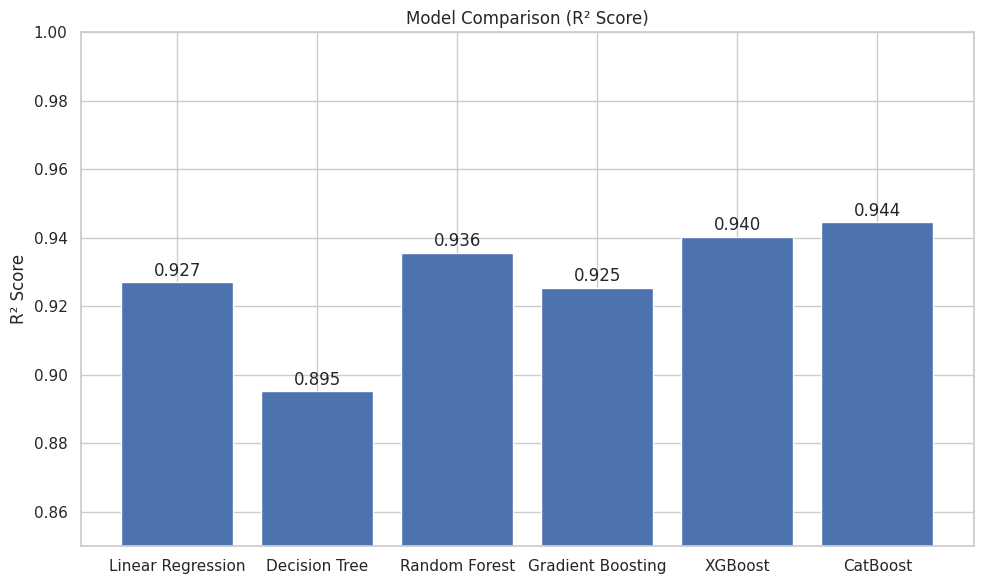

In [284]:
plt.figure(figsize=(10,6))

bars = plt.bar(
    model_results["Model"],
    model_results["R2"]
)

plt.title("Model Comparison (R² Score)")
plt.ylabel("R² Score")
plt.ylim(0.85,1)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.002,
        f"{bar.get_height():.3f}",
        ha='center'
    )

plt.tight_layout()
plt.show()

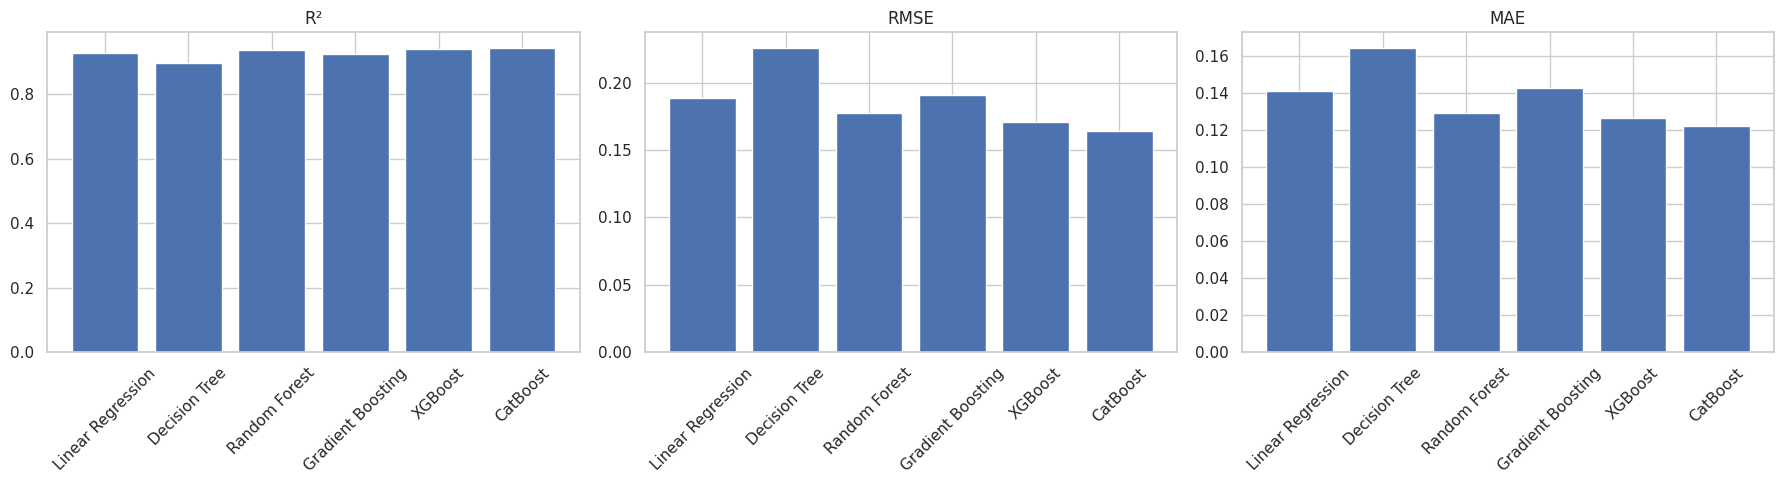

In [285]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

# R²
axes[0].bar(model_results["Model"], model_results["R2"])
axes[0].set_title("R²")
axes[0].tick_params(axis='x', rotation=45)

# RMSE
axes[1].bar(model_results["Model"], model_results["RMSE"])
axes[1].set_title("RMSE")
axes[1].tick_params(axis='x', rotation=45)

# MAE
axes[2].bar(model_results["Model"], model_results["MAE"])
axes[2].set_title("MAE")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.show()

## Model Comparison

Six regression models were evaluated using MAE, RMSE, and R².

CatBoost achieved the best overall performance with:

- Highest R² (0.944)
- Lowest RMSE (0.164)
- Lowest MAE (0.122)

XGBoost and Random Forest also performed well, demonstrating the effectiveness of ensemble tree-based methods for this regression problem.

Linear Regression provided a strong baseline despite its simplicity, while a single Decision Tree produced the weakest performance due to overfitting and limited generalization.

Based on these results, CatBoost was selected as the final model for further optimization.

# Hyperparameter Tuning

In [286]:
#Define the Parameter Grid
param_dist = {
    'regressor__iterations': [300, 500, 700, 1000],
    'regressor__depth': [4, 6, 8, 10],
    'regressor__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'regressor__l2_leaf_reg': [1, 3, 5, 7, 9],
    'regressor__bagging_temperature': [0, 1, 3, 5]
}

In [287]:
#Create RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=catboost_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring='r2',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [288]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['vehicle_age',
                                                                                'km_driven',
                                                                                'mileage',
                                                                                'engine',
                                                                                'max_power',
                                                                                'seats',
                                                                                'km_per_year',
                                                                                'log_km_driven']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy...
                                              CatBoostRegressor(depth=6, iterations=500, learning_rate=0.1, loss_function='RMSE', random_state=42, verbose=0))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'regressor__bagging_temperature': [0, 1,
                                                                           3,
                                                                           5],
                                        'regressor__depth': [4, 6, 8, 10],
                                        'regressor__iterations': [300, 500, 700,
                                                                  1000],
                                        'regressor__l2_leaf_reg': [1, 3, 5, 7,
                                                                   9],
                                        'regressor__learning_rate': [0.01, 0.03,
                                                                     0.05,
                                                                     0.1]},
                   random_state=42, scoring='r2', verbose=2)

In [289]:
print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'regressor__learning_rate': 0.1, 'regressor__l2_leaf_reg': 9, 'regressor__iterations': 1000, 'regressor__depth': 8, 'regressor__bagging_temperature': 0}


In [290]:
print("Best Cross Validation R²:")
print(random_search.best_score_)

Best Cross Validation R²:
0.9425699119747225


In [291]:
best_model = random_search.best_estimator_

In [293]:
y_pred_best = best_model.predict(X_test)

In [294]:
best_mae = mean_absolute_error(y_test, y_pred_best)

best_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_best)
)

best_r2 = r2_score(y_test, y_pred_best)

In [295]:
print("Optimized CatBoost")

print(f"MAE : {best_mae:.4f}")
print(f"RMSE: {best_rmse:.4f}")
print(f"R²  : {best_r2:.4f}")

Optimized CatBoost
MAE : 0.1210
RMSE: 0.1634
R²  : 0.9452


In [296]:
comparison = pd.DataFrame({
    "Version": ["Original CatBoost", "Optimized CatBoost"],
    "MAE": [cb_mae, best_mae],
    "RMSE": [cb_rmse, best_rmse],
    "R2": [cb_r2, best_r2]
})

comparison

,Version,MAE,RMSE,R2
0,Original CatBoost,0.122008,0.164490,0.944463
1,Optimized CatBoost,0.120981,0.163406,0.945193


In [304]:
cat_model = best_model.named_steps['regressor']

feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": cat_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
4,num__max_power,33.787744
0,num__vehicle_age,32.893537
3,num__engine,9.801894
2,num__mileage,2.871131
285,cat__transmission_type_Automatic,2.695205
281,cat__fuel_type_Diesel,2.180921
7,num__log_km_driven,1.977479
1,num__km_driven,1.633220
5,num__seats,1.294327
6,num__km_per_year,1.250285


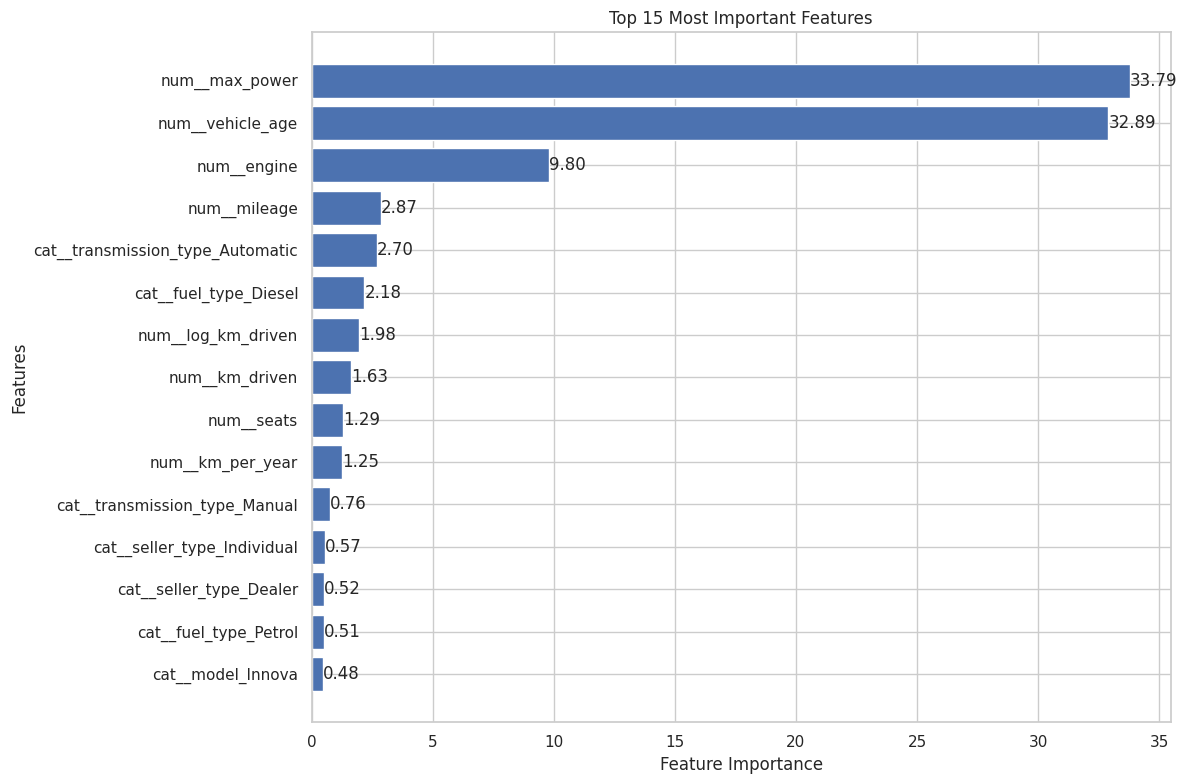

In [305]:
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Most Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

for index, value in enumerate(top_features["Importance"]):
    plt.text(value, index, f"{value:.2f}", va="center")

plt.tight_layout()
plt.show()

## Feature Importance Analysis

Feature importance analysis was performed using the optimized CatBoost model.

The results indicate that numerical variables such as **max_power**, **vehicle_age**, and **engine capacity** are among the most influential predictors of used car prices.

Several categorical features, particularly **brand**, also contribute significantly, reflecting the impact of manufacturer reputation on vehicle value.

Overall, the importance rankings are consistent with the earlier exploratory data analysis and correlation analysis, confirming that the model relies on meaningful predictors rather than noise.

In [298]:
import os

os.makedirs("saved_models", exist_ok=True)

In [301]:
trained_models = {
    "linear_regression": linear_model,
    "decision_tree": decision_tree_model,
    "random_forest": random_forest_model,
    "gradient_boosting": gradient_boosting_model,
    "xgboost": xgboost_model,
    "catboost": catboost_model,
    "optimized_catboost": best_model
}

In [303]:
import os
import joblib

os.makedirs("saved_models", exist_ok=True)

for name, model in trained_models.items():
    joblib.dump(model, f"saved_models/{name}.pkl")

print("All models have been saved successfully!")

All models have been saved successfully!
